# Fractal model — descriptive statistics

Runs the study across **GC, ES and NQ**, writing each symbol into its own
folder on the Desktop.

**Run order**

| cell | what |
|---|---|
| 1 | engine — defines everything, run once |
| 2 | helper functions — validation, baseline control, chart export |
| 3 | **driver** — loops the symbols and does everything |
| 4-7 | your original per-pairing chart/table cells (set `CSV_PATH` by hand) |

**What changed from the single-symbol version**

1. **`load_1min` resolves its defaults at call time.** The original signature
   was `def load_1min(path=FILE_PATH, ...)`, which freezes `FILE_PATH` when the
   cell runs. A symbol loop would have silently analysed the same instrument
   three times and written it out under three names. This is the one change you
   could not see going wrong.
2. **Twelve new pairings** — 30min, 2h and Daily against 1/2/3/5-minute entries.
3. **Session-anchored daily candles.** A plain `'1D'` resample cuts at midnight
   and splits the futures session in half. Daily bars now start at 18:00.
4. **Baseline control + validation**, run per symbol by the driver.
5. **Chart export** — four small CSVs per symbol, written to one shared
   `_export` folder ready to upload.


In [1]:
"""
================================================================================
FRACTAL MODEL — DESCRIPTIVE STATISTICS
================================================================================
Purpose: characterise what typically HAPPENS after a higher-timeframe liquidity
sweep is confirmed, so you can judge context, size a stop, and place targets.

This is descriptive only. No strategy, no edge claims, no optimisation.

WHAT IT MEASURES
  A  Event identification  C2 sweep+reclaim, CISD, T-spot
  B  Funnel                CISD confirm / equilibrium / XC2 / C4, with timings
  C  Sweep geometry        depth, reclaim distance, C2 range (pts, ATR, %)
  D  C2 close vs C1        where C2 closed inside the candle it swept
  E  C2 candle anatomy     body %, sweep-wick %, far-wick %, close direction
  F  Liquidity taken       PDH/PDL, PWH/PWL, ONH/ONL, IBH/IBL, PSH/PSL, equal-highs/lows
  G  Context               session, VWAP + bands, ATR regime, volume, year, direction
  H  MAE / MFE             two anchors x five horizons + to-invalidation,
                           in points / % of price / ATR / R, with percentiles
  J  Cross-tabs            funnel and excursions by every context factor,
                           plus two-way tables on the strongest interactions

NO LOOKAHEAD
  - HTF candles rebuilt from 1-min; C2 read only from CLOSED candles
  - the event timestamp is the moment the C2 candle closes
  - overnight/IB/prior-session levels are masked until their period completes
  - VWAP is cumulative; bias-style levels are shifted

CONVENTIONS
  - trading day 18:00 -> 17:00 ET, labelled by start date
  - week starts Sunday 18:00 ET
  - R = distance from entry to the C2 extreme (the natural structural stop)

USAGE
  set FILE_PATH and OUT_DIR, then:  python fractal_descriptive.py
  Each pairing writes one Excel workbook plus a per-event CSV.
================================================================================
"""

import os
import gc
import time
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

# ═══════════════════════════════════════════════════════════════════════
# CONFIG
# ═══════════════════════════════════════════════════════════════════════
# ── where the raw 1-min files live, and what they are called ──────────────
DATA_DIR = r"C:\Users\tammm\NQ and ES analysis"
FILE_TEMPLATE = '{symbol}_15y_1min.csv'        # GC_15y_1min.csv, ES_..., NQ_...
SYMBOLS = ['GC']

# Single-symbol fallbacks. The multi-symbol driver overrides both per symbol.
FILE_PATH = f'{DATA_DIR}\\' + FILE_TEMPLATE.format(symbol=SYMBOLS[-1])
OUT_DIR = r"C:\Users\tammm\NQ and ES analysis\fractal_stats"

START_DATE = '2019-06-01'
END_DATE = '2025-12-31'

# The eleven original pairings, plus twelve on 30min / 2h / Daily.
# 30, 120 and 1380 minutes all divide cleanly by 1, 2, 3 and 5, so none of the
# new twelve has the 2min/15min problem (7.5 entry bars per candle).
PAIRINGS_ORIGINAL = [
    ('1min', '15min'), ('2min', '15min'), ('3min', '15min'),
    ('1min', '1h'), ('2min', '1h'), ('3min', '1h'), ('5min', '1h'),
    ('1min', '4h'), ('2min', '4h'), ('3min', '4h'), ('5min', '4h'),
]
PAIRINGS_NEW = [
    ('1min', '30min'), ('2min', '30min'), ('3min', '30min'), ('5min', '30min'),
    ('1min', '2h'),    ('2min', '2h'),    ('3min', '2h'),    ('5min', '2h'),
    ('1min', '1D'),    ('2min', '1D'),    ('3min', '1D'),    ('5min', '1D'),
]
PAIRINGS = PAIRINGS_ORIGINAL + PAIRINGS_NEW

# Daily candles are anchored to the 18:00 futures open, not midnight —
# see resample_tf. Set to None for plain calendar days.
SESSION_ANCHOR_HOURS = 18
DAILY_RULES = {'1D', 'D', '1d'}

TICK = 0.25
ATR_LEN = 14
STOP_BUFFER = 1.0            # stop sits this far beyond the C2 extreme
SWING_STRENGTH = 2           # for equal-high/low clustering
EQ_LOOKBACK = 100            # bars of swing history for equal-level pools
EQ_TOL_TICKS = 4
EQ_MIN_TOUCHES = 2
LIQ_TOL_PTS = 5.0            # "at" a level
MIN_GROUP_N = 200            # suppress thin cross-tab rows

# MAE/MFE horizons in MINUTES (wall-clock, so comparable across LTFs)
HORIZONS_MIN = [15, 30, 60, 120, 240]
MAX_HOLD_MIN = 240

SESSION_ORDER = ['Globex', 'Asia', 'London', 'NY_AM', 'NY_PM']
LOW_LVLS = ['PDL', 'PWL', 'ONL', 'IBL', 'PSL', 'EQL']
HIGH_LVLS = ['PDH', 'PWH', 'ONH', 'IBH', 'PSH', 'EQH']
LIQ_PRIORITY = ['PWL', 'PWH', 'PDL', 'PDH', 'ONL', 'ONH',
                'PSL', 'PSH', 'IBL', 'IBH', 'EQL', 'EQH']


def hour_to_session(h):
    if 18 <= h < 20: return 'Globex'
    if h >= 20 or h < 2: return 'Asia'
    if 2 <= h < 8: return 'London'
    if 8 <= h < 12: return 'NY_AM'
    if 12 <= h < 17: return 'NY_PM'
    return 'Other'


# ═══════════════════════════════════════════════════════════════════════
# 1. DATA + CONTEXT (computed once on the 1-min series)
# ═══════════════════════════════════════════════════════════════════════
def load_1min(path=None, start=None, end=None):
    """Load the 1-min series.

    NOTE the late-bound defaults. The original signature was
        def load_1min(path=FILE_PATH, start=START_DATE, end=END_DATE)
    which freezes FILE_PATH at the moment this cell runs. Reassigning
    FILE_PATH afterwards would have had NO effect, so a loop over GC/ES/NQ
    would have silently analysed the same instrument three times and written
    it out under three different symbol names. Resolving the globals at call
    time instead makes the multi-symbol driver actually work.
    """
    path = FILE_PATH if path is None else path
    start = START_DATE if start is None else start
    end = END_DATE if end is None else end
    df = pd.read_csv(path)
    df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
    df.set_index('Datetime', inplace=True)
    df = df.loc[start:end]
    cols = ['Open', 'High', 'Low', 'Close'] + (['Volume'] if 'Volume' in df.columns else [])
    return df[cols].copy()


def build_context(m1):
    d = m1.copy()
    # trading day 18:00 -> 17:00 ET, labelled by START date
    ntd = (d.index - pd.Timedelta(hours=18)).normalize()
    d['NY_Day'] = ntd
    d['Week'] = ntd - pd.to_timedelta((ntd.dayofweek + 1) % 7, unit='D')
    d['Hour'] = d.index.hour
    d['Session'] = d['Hour'].map(hour_to_session)

    # ---- VWAP (cumulative within day / week) + sigma bands
    if 'Volume' in d.columns:
        tp = (d['High'] + d['Low'] + d['Close']) / 3
        pv = tp * d['Volume']
        for tag, key in (('D', 'NY_Day'), ('W', 'Week')):
            cpv = pv.groupby(d[key]).cumsum()
            cv = d['Volume'].groupby(d[key]).cumsum()
            vwap = cpv / cv
            d[f'vwap_{tag}'] = vwap
            cpv2 = (tp ** 2 * d['Volume']).groupby(d[key]).cumsum()
            sd = np.sqrt(((cpv2 / cv) - vwap ** 2).clip(lower=0))
            for bmul in (1, 2):
                d[f'vwap_{tag}_u{bmul}'] = vwap + bmul * sd
                d[f'vwap_{tag}_l{bmul}'] = vwap - bmul * sd

    # ---- prior day / prior week
    daily = d.groupby('NY_Day').agg(H=('High', 'max'), L=('Low', 'min'), C=('Close', 'last'))
    daily[['PDH', 'PDL', 'PDC']] = daily[['H', 'L', 'C']].shift(1)
    weekly = d.groupby('Week').agg(H=('High', 'max'), L=('Low', 'min'), C=('Close', 'last'))
    weekly[['PWH', 'PWL', 'PWC']] = weekly[['H', 'L', 'C']].shift(1)
    d = d.join(daily[['PDH', 'PDL', 'PDC']], on='NY_Day')
    d = d.join(weekly[['PWH', 'PWL', 'PWC']], on='Week')

    # ---- overnight range (Globex+Asia+London), only usable from 08:00 ET
    on = d[d['Session'].isin(['Globex', 'Asia', 'London'])].groupby('NY_Day').agg(
        ONH=('High', 'max'), ONL=('Low', 'min'))
    d = d.join(on, on='NY_Day')
    mask = (d['Hour'] >= 8) & (d['Hour'] < 18)
    d['ONH'] = d['ONH'].where(mask)
    d['ONL'] = d['ONL'].where(mask)

    # ---- initial balance 08:00-09:00 ET, usable from 09:00
    ib = d[(d['Hour'] >= 8) & (d['Hour'] < 9)].groupby('NY_Day').agg(
        IBH=('High', 'max'), IBL=('Low', 'min'))
    d = d.join(ib, on='NY_Day')
    d['IBH'] = d['IBH'].where(d['Hour'] >= 9)
    d['IBL'] = d['IBL'].where(d['Hour'] >= 9)

    # ---- prior session extremes
    d['_sid'] = (d['Session'] != d['Session'].shift()).cumsum()
    ss = d.groupby('_sid').agg(SH=('High', 'max'), SL=('Low', 'min'))
    ss[['PSH', 'PSL']] = ss[['SH', 'SL']].shift(1)
    d = d.join(ss[['PSH', 'PSL']], on='_sid')
    return d


def resample_tf(m1, rule):
    """Resample the 1-min series to `rule`.

    build_context already defines the trading day as 18:00 -> 17:00 ET. A plain
    '1D' resample cuts at MIDNIGHT, which would slice the futures session in
    half and put the back of one session and the front of the next into every
    'daily' candle. So daily bars are anchored to 18:00 to match.

    30min and 2h need no special handling — 18:00 is already a bin edge for
    both. (The existing 4h is NOT session-aligned: midnight-anchored 4h bins
    run 00-04 ... 16-20, so the 16:00 bar straddles the 17:00 close and 18:00
    open. Unchanged from the original study.)
    """
    agg = {'Open': 'first', 'High': 'max', 'Low': 'min', 'Close': 'last'}
    if 'Volume' in m1.columns:
        agg['Volume'] = 'sum'

    if rule in DAILY_RULES and SESSION_ANCHOR_HOURS:
        off = pd.Timedelta(hours=SESSION_ANCHOR_HOURS)
        shifted = m1.copy()
        shifted.index = shifted.index - off
        out = (shifted.resample(rule, label='left', closed='left')
                      .agg(agg).dropna(subset=['Open']))
        out.index = out.index + off
        return out

    return m1.resample(rule, label='left', closed='left').agg(agg).dropna(subset=['Open'])


def atr(df, n=ATR_LEN):
    h, l, c = df['High'], df['Low'], df['Close'].shift(1)
    tr = pd.concat([h - l, (h - c).abs(), (l - c).abs()], axis=1).max(axis=1)
    return tr.rolling(n, min_periods=1).mean()


# ═══════════════════════════════════════════════════════════════════════
# 2. A — C2 DETECTION
# ═══════════════════════════════════════════════════════════════════════
def detect_c2(htf):
    """Sweep the prior HTF candle's extreme and close back inside it."""
    O, H, L, C = (htf[x].values for x in ('Open', 'High', 'Low', 'Close'))
    pH, pL = np.roll(H, 1), np.roll(L, 1)
    bull = (L < pL) & (C > pL)
    bear = (H > pH) & (C < pH)
    ok = np.zeros(len(htf), bool); ok[1:] = True
    bull &= ok; bear &= ok
    idx = np.where(bull | bear)[0]
    if len(idx) == 0:
        return pd.DataFrame()
    b = bull[idx]
    pc = np.roll(C, 1)[idx]
    po = np.roll(O, 1)[idx]
    return pd.DataFrame({
        'c2_bar': idx, 'is_bull': b,
        'swept_level': np.where(b, pL[idx], pH[idx]),
        'c2_extreme': np.where(b, L[idx], H[idx]),
        'c2_open': O[idx], 'c2_high': H[idx], 'c2_low': L[idx], 'c2_close': C[idx],
        'c2_eq': (H[idx] + L[idx]) / 2,
        'c2_range': H[idx] - L[idx],
        'sweep_depth': np.where(b, pL[idx] - L[idx], H[idx] - pH[idx]),
        'reclaim_dist': np.where(b, C[idx] - pL[idx], pH[idx] - C[idx]),
        'c2_vol': htf['Volume'].values[idx] if 'Volume' in htf.columns else np.nan,
        'c1_open': po, 'c1_high': np.roll(H, 1)[idx], 'c1_low': np.roll(L, 1)[idx],
        'c1_close': pc,
    })


# ═══════════════════════════════════════════════════════════════════════
# 3. A — CISD LEVELS (LTF). Optimised: only evaluated at candidate bars.
# ═══════════════════════════════════════════════════════════════════════
def cisd_levels(ltf, pid):
    """Level = open of the down(up)-candle run that produced the period extreme."""
    O, H, L, C = (ltf[x].values for x in ('Open', 'High', 'Low', 'Close'))
    n = len(ltf)
    up, dw, eqc = C > O, C < O, C == O

    s = pd.Series(pid)
    run_min = pd.Series(L).groupby(s).cummin().values
    run_max = pd.Series(H).groupby(s).cummax().values
    per_min = pd.Series(L).groupby(s).min()
    per_max = pd.Series(H).groupby(s).max()
    prev_min = s.map(per_min.shift(1)).values
    prev_max = s.map(per_max.shift(1)).values

    cand_b = np.where((L == run_min) & (L < prev_min))[0]
    cand_s = np.where((H == run_max) & (H > prev_max))[0]

    bl = np.full(n, np.nan); bs = np.full(n, np.nan)
    for i in cand_b:
        lvl = np.nan
        if (dw[i] or eqc[i]) and i >= 1 and (up[i - 1] or eqc[i - 1]) and not (eqc[i] and eqc[i - 1]):
            lvl = O[i]
        else:
            for k in range(2, 11):
                j = i - k
                if j < 1 or L[j] < L[i]:
                    break
                if (up[j] or eqc[j]) and dw[j + 1]:
                    b0 = j + 1
                    lvl = O[b0]
                    for q in range(b0, i + 1):
                        if O[q] > lvl and dw[q]:
                            lvl = O[q]
                    if lvl < O[i]:
                        lvl = H[i] if C[i] > O[i] else O[i]
                    break
        if np.isfinite(lvl):
            bl[i] = lvl
    for i in cand_s:
        lvl = np.nan
        if (up[i] or eqc[i]) and i >= 1 and (dw[i - 1] or eqc[i - 1]) and not (eqc[i] and eqc[i - 1]):
            lvl = O[i]
        else:
            for k in range(2, 11):
                j = i - k
                if j < 1 or H[j] > H[i]:
                    break
                if (dw[j] or eqc[j]) and up[j + 1]:
                    b0 = j + 1
                    lvl = O[b0]
                    for q in range(b0, i + 1):
                        if O[q] < lvl and up[q]:
                            lvl = O[q]
                    if lvl > O[i]:
                        lvl = L[i] if C[i] < O[i] else O[i]
                    break
        if np.isfinite(lvl):
            bs[i] = lvl
    return pd.Series(bl).ffill().values, pd.Series(bs).ffill().values


# ═══════════════════════════════════════════════════════════════════════
# 4. B — FUNNEL TRACKING
# ═══════════════════════════════════════════════════════════════════════
def track(c2, ltf, htf, bull_lvl, bear_lvl):
    O, H, L, C = (ltf[x].values for x in ('Open', 'High', 'Low', 'Close'))
    n = len(ltf)
    li = ltf.index.values
    close_pos = np.searchsorted(li, htf.index.values, side='left')

    rows = []
    for _, r in c2.iterrows():
        cb = int(r['c2_bar'])
        if cb + 3 >= len(close_pos):
            continue
        sp = int(close_pos[cb + 1])
        if sp >= n:
            continue
        is_bull = bool(r['is_bull'])
        ext = float(r['c2_extreme']); eq = float(r['c2_eq'])
        lvl = bull_lvl[sp - 1] if is_bull else bear_lvl[sp - 1]

        early = False
        seg0, seg1 = int(close_pos[cb]), sp
        if np.isfinite(lvl) and seg1 > seg0:
            early = bool((C[seg0:seg1] > lvl).any() if is_bull else (C[seg0:seg1] < lvl).any())

        c3_end = int(close_pos[cb + 2])
        horizon = min(int(close_pos[cb + 3]), n)
        c3_open = O[sp]
        ts_span = abs(c3_open - eq)

        cisd_p = eq_p = xc2_p = None
        deepest = 0.0
        for p in range(sp, horizon):
            if cisd_p is None and np.isfinite(lvl):
                if (C[p] > lvl) if is_bull else (C[p] < lvl):
                    cisd_p = p
            pen = (c3_open - L[p]) if is_bull else (H[p] - c3_open)
            if ts_span > 0:
                deepest = max(deepest, min(pen / ts_span, 2.0))
            if eq_p is None and ((L[p] <= eq) if is_bull else (H[p] >= eq)):
                eq_p = p
            if (L[p] < ext) if is_bull else (H[p] > ext):
                xc2_p = p
                break

        rows.append(dict(
            c2_bar=cb, c2_time=htf.index[cb], event_time=li[sp], start_pos=sp,
            is_bull=is_bull, entry_price=C[sp],
            cisd_level=lvl, cisd_early=early,
            cisd_confirmed=cisd_p is not None,
            cisd_bars=(cisd_p - sp) if cisd_p is not None else np.nan,
            cisd_time=li[cisd_p] if cisd_p is not None else pd.NaT,
            cisd_price=C[cisd_p] if cisd_p is not None else np.nan,
            cisd_pos=cisd_p if cisd_p is not None else -1,
            eq_reached=eq_p is not None,
            eq_bars=(eq_p - sp) if eq_p is not None else np.nan,
            tspot_depth=deepest,
            xc2=xc2_p is not None,
            xc2_bars=(xc2_p - sp) if xc2_p is not None else np.nan,
            reached_c4=(xc2_p is None or xc2_p >= c3_end),
        ))
    return pd.DataFrame(rows)


# ═══════════════════════════════════════════════════════════════════════
# 5. E/F — CANDLE ANATOMY, SWINGS, EQUAL LEVELS, LIQUIDITY
# ═══════════════════════════════════════════════════════════════════════
def swings_fast(H, L, k=SWING_STRENGTH):
    n = len(H)
    if n < 2 * k + 1:
        return (np.array([]),) * 4
    wh = sliding_window_view(H, 2 * k + 1)
    wl = sliding_window_view(L, 2 * k + 1)
    c = np.arange(k, n - k)
    ish = H[c] == wh.max(axis=1)
    isl = L[c] == wl.min(axis=1)
    return c[ish] + k, H[c][ish], c[isl] + k, L[c][isl]


def equal_levels_at(sw_bar, sw_px, positions,
                    lookback=EQ_LOOKBACK, tol=EQ_TOL_TICKS * TICK, min_touch=EQ_MIN_TOUCHES):
    """Nearest tight cluster of >=min_touch swing points, evaluated only at `positions`."""
    out = np.full(len(positions), np.nan)
    if len(sw_bar) == 0:
        return out
    for k, i in enumerate(positions):
        lo = np.searchsorted(sw_bar, i - lookback, 'left')
        hi = np.searchsorted(sw_bar, i, 'left')
        if hi - lo < min_touch:
            continue
        px = np.sort(sw_px[lo:hi])
        if len(px) < min_touch:
            continue
        d = px[min_touch - 1:] - px[:len(px) - min_touch + 1]
        ok = np.where(d <= tol)[0]
        if len(ok):
            j = ok[-1]
            out[k] = px[j:j + min_touch].mean()
    return out


def add_anatomy(ev, c2):
    """D + E: C2 close relative to C1, and C2 candle anatomy (direction-normalised)."""
    d = ev.merge(c2, on='c2_bar', how='left', suffixes=('', '_c2'))
    if 'is_bull_c2' in d.columns:
        d = d.drop(columns=['is_bull_c2'])
    bull = d['is_bull'].values
    rng = d['c2_range'].replace(0, np.nan)

    # D: where C2 closed inside C1 (0% = swept level, 100% = C1 far extreme)
    c1r = (d['c1_high'] - d['c1_low']).replace(0, np.nan)
    d['c2c_in_c1'] = np.where(bull, (d['c2_close'] - d['c1_low']) / c1r,
                              (d['c1_high'] - d['c2_close']) / c1r) * 100
    d['closed_above_c1_mid'] = d['c2c_in_c1'] >= 50
    d['closed_beyond_c1'] = d['c2c_in_c1'] >= 100
    d['closed_beyond_c1_open'] = np.where(bull, d['c2_close'] > d['c1_open'],
                                          d['c2_close'] < d['c1_open'])
    d['c1_was_opposite'] = np.where(bull, d['c1_close'] < d['c1_open'],
                                    d['c1_close'] > d['c1_open'])

    # E: anatomy
    body = (d['c2_close'] - d['c2_open']).abs()
    upper = d['c2_high'] - d[['c2_open', 'c2_close']].max(axis=1)
    lower = d[['c2_open', 'c2_close']].min(axis=1) - d['c2_low']
    d['c2_body_pct'] = body / rng * 100
    d['sweep_wick_pct'] = np.where(bull, lower, upper) / rng * 100
    d['far_wick_pct'] = np.where(bull, upper, lower) / rng * 100
    with np.errstate(divide='ignore', invalid='ignore'):
        d['wick_body_ratio'] = np.where(bull, lower, upper) / body.replace(0, np.nan)
    d['close_with_reclaim'] = np.where(bull, d['c2_close'] > d['c2_open'],
                                       d['c2_close'] < d['c2_open'])
    return d


def add_context_and_liquidity(d, ctx, ltf, eql, eqh):
    keep = [c for c in ['Session', 'Hour', 'NY_Day', 'vwap_D', 'vwap_W',
                        'vwap_D_u1', 'vwap_D_l1', 'vwap_D_u2', 'vwap_D_l2',
                        'PDH', 'PDL', 'PDC', 'PWH', 'PWL', 'ONH', 'ONL',
                        'IBH', 'IBL', 'PSH', 'PSL'] if c in ctx.columns]
    c = ctx[keep].reset_index()
    c.columns = ['ts'] + keep
    c['ts'] = pd.DatetimeIndex(c['ts']).astype('datetime64[ns]')
    d = d.copy()
    d['ts'] = pd.DatetimeIndex(d['event_time']).astype('datetime64[ns]')
    d = d.sort_values('ts')
    d = pd.merge_asof(d, c.sort_values('ts'), on='ts', direction='backward')

    sp = d['start_pos'].values.astype(int)
    d['EQL'] = eql[np.clip(sp, 0, len(eql) - 1)]
    d['EQH'] = eqh[np.clip(sp, 0, len(eqh) - 1)]

    for tag in ['D', 'W']:
        if f'vwap_{tag}' in d.columns:
            d[f'vwap_{tag}_dist'] = d['swept_level'] - d[f'vwap_{tag}']
            d[f'above_vwap_{tag}'] = d[f'vwap_{tag}_dist'] > 0
    if 'vwap_D_l2' in d.columns:
        d['vwap_band'] = np.select(
            [d['swept_level'] <= d['vwap_D_l2'], d['swept_level'] <= d['vwap_D_l1'],
             d['swept_level'] >= d['vwap_D_u2'], d['swept_level'] >= d['vwap_D_u1']],
            ['below -2sd', '-1 to -2sd', 'above +2sd', '+1 to +2sd'], default='inside +/-1sd')

    lows = np.array([[r.get(x, np.nan) for x in LOW_LVLS] for _, r in d.iterrows()], float)
    highs = np.array([[r.get(x, np.nan) for x in HIGH_LVLS] for _, r in d.iterrows()], float)
    lvl = np.where(d['is_bull'].values[:, None], lows, highs)
    names = np.array(LOW_LVLS)
    names_h = np.array(HIGH_LVLS)
    dist = np.abs(lvl - d['swept_level'].values[:, None])

    matched, primary, nearest, ndist = [], [], [], []
    for i in range(len(d)):
        nm = names if d['is_bull'].iat[i] else names_h
        dd = dist[i]
        ok = np.where(dd <= LIQ_TOL_PTS)[0]
        ms = [nm[j] for j in ok]
        matched.append('+'.join(ms) if ms else 'none')
        p = 'none'
        for cand in LIQ_PRIORITY:
            if cand in ms:
                p = cand
                break
        if p == 'none' and ms:
            p = ms[0]
        primary.append(p)
        if np.isfinite(dd).any():
            j = int(np.nanargmin(dd))
            nearest.append(nm[j]); ndist.append(dd[j])
        else:
            nearest.append('none'); ndist.append(np.nan)
    d['liq_matched'] = matched
    d['liq_primary'] = primary
    d['liq_nearest'] = nearest
    d['liq_dist'] = ndist
    d['took_named_liquidity'] = d['liq_matched'] != 'none'
    return d


def add_normalisers(d, atr_ltf, vol_ma_htf):
    sp = d['start_pos'].values.astype(int)
    a = atr_ltf[np.clip(sp, 0, len(atr_ltf) - 1)]
    d['atr'] = a
    px = d['entry_price'].replace(0, np.nan)
    for col in ['sweep_depth', 'reclaim_dist', 'c2_range']:
        d[f'{col}_atr'] = d[col] / a
        d[f'{col}_pct'] = d[col] / px * 100
    d['sweep_vs_c2range'] = d['sweep_depth'] / d['c2_range'].replace(0, np.nan) * 100
    d['reclaim_vs_c2range'] = d['reclaim_dist'] / d['c2_range'].replace(0, np.nan) * 100
    if 'c2_vol' in d.columns and vol_ma_htf is not None:
        cb = d['c2_bar'].values.astype(int)
        vm = vol_ma_htf[np.clip(cb, 0, len(vol_ma_htf) - 1)]
        d['vol_ratio'] = d['c2_vol'] / np.where(vm > 0, vm, np.nan)
    d['year'] = pd.DatetimeIndex(d['event_time']).year
    try:
        d['atr_regime'] = pd.qcut(d['atr'], 4,
                                  labels=['Q1 calm', 'Q2', 'Q3', 'Q4 volatile'], duplicates='drop')
    except Exception:
        d['atr_regime'] = 'n/a'
    # binning for cross-tabs
    d['c2c_bin'] = pd.cut(d['c2c_in_c1'], [0, 10, 25, 50, 75, 100, 1e9],
                          labels=['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%'])
    d['body_bin'] = pd.cut(d['c2_body_pct'], [0, 10, 20, 35, 50, 70, 100],
                           labels=['0-10 doji', '10-20', '20-35', '35-50', '50-70', '70-100'])
    d['sweep_wick_bin'] = pd.cut(d['sweep_wick_pct'], [0, 20, 35, 50, 65, 100],
                                 labels=['0-20', '20-35', '35-50', '50-65', '65-100'])
    d['far_wick_bin'] = pd.cut(d['far_wick_pct'], [0, 10, 20, 35, 50, 100],
                               labels=['0-10', '10-20', '20-35', '35-50', '50-100'])
    d['sweep_depth_bin'] = pd.qcut(d['sweep_depth_atr'], 4,
                                   labels=['Q1 shallow', 'Q2', 'Q3', 'Q4 deep'], duplicates='drop')
    return d


# ═══════════════════════════════════════════════════════════════════════
# 6. H — MAE / MFE
# ═══════════════════════════════════════════════════════════════════════
def excursions(times, entry_px, is_bull, stop_px, atr_v, m1,
               inval_px, horizons=HORIZONS_MIN, max_min=MAX_HOLD_MIN, prefix=''):
    MI = m1.index.values
    MH = m1['High'].values
    ML = m1['Low'].values
    NM = len(m1)
    st = np.searchsorted(MI, pd.DatetimeIndex(times).astype('datetime64[ns]').values, side='right')
    n = len(entry_px)
    stop_dist = np.abs(entry_px - stop_px)

    cols = {}
    for h in horizons:
        cols[f'mfe_{h}m'] = np.full(n, np.nan)
        cols[f'mae_{h}m'] = np.full(n, np.nan)
    for k in ['mfe_inval', 'mae_inval', 'bars_to_mfe', 'bars_to_mae',
              'heat_before_mfe', 'bars_to_inval']:
        cols[k] = np.full(n, np.nan)

    for j in range(n):
        s0 = st[j]
        if s0 >= NM or not np.isfinite(entry_px[j]):
            continue
        e = min(s0 + max_min, NM)
        hi, lo = MH[s0:e], ML[s0:e]
        if len(hi) == 0:
            continue
        if is_bull[j]:
            fav, adv = hi - entry_px[j], entry_px[j] - lo
        else:
            fav, adv = entry_px[j] - lo, hi - entry_px[j]
        for h in horizons:
            k = min(h, len(fav))
            if k > 0:
                cols[f'mfe_{h}m'][j] = fav[:k].max()
                cols[f'mae_{h}m'][j] = adv[:k].max()
        stop_i = len(fav)
        if np.isfinite(inval_px[j]):
            br = (lo < inval_px[j]) if is_bull[j] else (hi > inval_px[j])
            if br.any():
                stop_i = int(np.argmax(br)) + 1
                cols['bars_to_inval'][j] = stop_i
        f2, a2 = fav[:stop_i], adv[:stop_i]
        if len(f2):
            cols['mfe_inval'][j] = f2.max()
            cols['mae_inval'][j] = a2.max()
            im = int(np.argmax(f2))
            cols['bars_to_mfe'][j] = im
            cols['bars_to_mae'][j] = int(np.argmax(a2))
            cols['heat_before_mfe'][j] = a2[:im + 1].max()

    out = pd.DataFrame(cols)
    for c in [c for c in out.columns if c.startswith(('mfe_', 'mae_', 'heat_'))]:
        out[c + '_atr'] = out[c] / atr_v
        out[c + '_R'] = out[c] / np.where(stop_dist > 0, stop_dist, np.nan)
        out[c + '_pct'] = out[c] / np.where(entry_px > 0, entry_px, np.nan) * 100
    out['stop_dist'] = stop_dist
    return out.add_prefix(prefix)


# ═══════════════════════════════════════════════════════════════════════
# 7. TABLES
# ═══════════════════════════════════════════════════════════════════════
def describe_cols(df, cols, qs=(0.25, 0.5, 0.75, 0.9, 0.95)):
    rows = []
    for c in cols:
        if c not in df.columns:
            continue
        s = df[c].replace([np.inf, -np.inf], np.nan).dropna()
        if len(s) < 30:
            continue
        r = {'metric': c, 'n': len(s), 'mean': s.mean()}
        for q in qs:
            r[f'p{int(q * 100)}'] = s.quantile(q)
        rows.append(r)
    return pd.DataFrame(rows).round(4)


def funnel_row(d, label):
    if len(d) == 0:
        return None
    return dict(
        scope=label, n=len(d),
        cisd_pct=round(d['cisd_confirmed'].mean() * 100, 1),
        early_cisd_pct=round(d['cisd_early'].mean() * 100, 1),
        cisd_bars_med=round(d['cisd_bars'].median(), 1),
        eq_reached_pct=round(d['eq_reached'].mean() * 100, 1),
        eq_bars_med=round(d['eq_bars'].median(), 1),
        xc2_pct=round(d['xc2'].mean() * 100, 1),
        xc2_bars_med=round(d['xc2_bars'].median(), 1),
        reached_c4_pct=round(d['reached_c4'].mean() * 100, 1),
    )


def funnel_by(d, col, min_n=MIN_GROUP_N):
    rows = []
    for k, g in d.groupby(col, observed=True):
        if len(g) < min_n:
            continue
        r = funnel_row(g, str(k))
        if r:
            rows.append(r)
    return pd.DataFrame(rows)


def excursion_by(d, col, metrics, min_n=MIN_GROUP_N):
    rows = []
    for k, g in d.groupby(col, observed=True):
        if len(g) < min_n:
            continue
        r = {'group': str(k), 'n': len(g)}
        for m in metrics:
            if m in g.columns:
                s = g[m].replace([np.inf, -np.inf], np.nan).dropna()
                if len(s):
                    r[f'{m}_med'] = round(s.median(), 3)
                    r[f'{m}_p75'] = round(s.quantile(.75), 3)
                    r[f'{m}_p90'] = round(s.quantile(.9), 3)
        rows.append(r)
    return pd.DataFrame(rows)


def two_way(d, idx, col, val='reached_c4'):
    p = d.pivot_table(index=idx, columns=col, values=val, aggfunc='mean', observed=True) * 100
    n = d.pivot_table(index=idx, columns=col, values=val, aggfunc='size', observed=True)
    return p.round(1).reset_index(), n.reset_index()


GROUPS = ['is_bull', 'Session', 'liq_primary', 'took_named_liquidity', 'vwap_band',
          'atr_regime', 'year', 'c2c_bin', 'body_bin', 'sweep_wick_bin',
          'far_wick_bin', 'sweep_depth_bin', 'close_with_reclaim',
          'closed_beyond_c1', 'cisd_confirmed', 'cisd_early']


def build_tables(d):
    t = {}
    # B funnel
    t['funnel_overall'] = pd.DataFrame([funnel_row(d, 'ALL')])
    cis = d[d['cisd_confirmed']]
    noc = d[~d['cisd_confirmed']]
    t['funnel_conditional'] = pd.DataFrame([
        dict(stage='C2 forms', n=len(d), pct=100.0),
        dict(stage='CISD confirms', n=len(cis), pct=round(len(cis) / max(len(d), 1) * 100, 1)),
        dict(stage='  ...then XC2', n=int(cis['xc2'].sum()),
             pct=round(cis['xc2'].mean() * 100, 1) if len(cis) else np.nan),
        dict(stage='  ...reaches C4', n=int(cis['reached_c4'].sum()),
             pct=round(cis['reached_c4'].mean() * 100, 1) if len(cis) else np.nan),
        dict(stage='CISD fails', n=len(noc), pct=round(len(noc) / max(len(d), 1) * 100, 1)),
        dict(stage='  ...XC2', n=int(noc['xc2'].sum()),
             pct=round(noc['xc2'].mean() * 100, 1) if len(noc) else np.nan),
    ])
    for g in GROUPS:
        if g in d.columns:
            tb = funnel_by(d, g)
            if len(tb):
                t[f'fn_{g}'[:31]] = tb

    # C sweep geometry
    t['geometry'] = describe_cols(d, ['sweep_depth', 'sweep_depth_atr', 'sweep_depth_pct',
                                      'reclaim_dist', 'reclaim_dist_atr', 'reclaim_dist_pct',
                                      'c2_range', 'c2_range_atr', 'c2_range_pct',
                                      'sweep_vs_c2range', 'reclaim_vs_c2range'])
    # D/E anatomy
    t['anatomy'] = describe_cols(d, ['c2c_in_c1', 'c2_body_pct', 'sweep_wick_pct',
                                     'far_wick_pct', 'wick_body_ratio', 'tspot_depth'])
    t['anatomy_flags'] = pd.DataFrame([dict(
        closed_above_c1_mid_pct=round(d['closed_above_c1_mid'].mean() * 100, 1),
        closed_beyond_c1_pct=round(d['closed_beyond_c1'].mean() * 100, 1),
        closed_beyond_c1_open_pct=round(d['closed_beyond_c1_open'].mean() * 100, 1),
        c1_was_opposite_pct=round(d['c1_was_opposite'].mean() * 100, 1),
        close_with_reclaim_pct=round(d['close_with_reclaim'].mean() * 100, 1))])
    # F liquidity
    t['liquidity_mix'] = d['liq_primary'].value_counts().rename_axis('level') \
        .reset_index(name='n')

    # H excursions, both anchors
    for pre, lab in [('c2_', 'from C2 close'), ('ci_', 'from CISD')]:
        pts = [f'{pre}{p}_{h}m' for p in ['mae', 'mfe'] for h in HORIZONS_MIN] + \
              [f'{pre}mae_inval', f'{pre}mfe_inval']
        t[f'exc_{pre}points'[:31]] = describe_cols(d, pts)
        t[f'exc_{pre}pct'[:31]] = describe_cols(d, [c + '_pct' for c in pts])
        t[f'exc_{pre}R'[:31]] = describe_cols(d, [c + '_R' for c in pts] +
                                              [f'{pre}heat_before_mfe_R'])
        t[f'exc_{pre}atr'[:31]] = describe_cols(d, [c + '_atr' for c in pts])
        t[f'exc_{pre}timing'[:31]] = describe_cols(
            d, [f'{pre}bars_to_mfe', f'{pre}bars_to_mae', f'{pre}bars_to_inval'])

    # J cross-tabs on excursions
    M = ['ci_mae_inval_R', 'ci_mfe_inval_R', 'ci_heat_before_mfe_R',
         'ci_mae_60m', 'ci_mfe_60m', 'ci_mae_60m_pct', 'ci_mfe_60m_pct']
    for g in ['Session', 'atr_regime', 'c2c_bin', 'body_bin', 'sweep_wick_bin',
              'liq_primary', 'is_bull', 'year']:
        if g in d.columns:
            tb = excursion_by(d, g, M)
            if len(tb):
                t[f'ex_{g}'[:31]] = tb

    # J two-way tables
    for a, b in [('c2c_bin', 'body_bin'), ('c2c_bin', 'sweep_wick_bin'),
                 ('c2c_bin', 'close_with_reclaim'), ('c2c_bin', 'Session'),
                 ('sweep_wick_bin', 'body_bin')]:
        if a in d.columns and b in d.columns:
            p, nn = two_way(d, a, b)
            t[f'2w_{a}_x_{b}'[:31]] = p
            t[f'2wN_{a}_x_{b}'[:31]] = nn
    return t


# ═══════════════════════════════════════════════════════════════════════
# 8. PIPELINE
# ═══════════════════════════════════════════════════════════════════════
def run_pairing(ctx, m1, ltf_rule, htf_rule, out_dir):
    tag = f'{ltf_rule}_{htf_rule}'
    t0 = time.time()
    ltf = resample_tf(m1, ltf_rule)
    htf = resample_tf(m1, htf_rule)
    c2 = detect_c2(htf)
    if c2.empty:
        print(f'  {tag}: no C2 events'); return None
    pid = np.searchsorted(htf.index.values, ltf.index.values, side='right') - 1
    bl, bs = cisd_levels(ltf, pid)
    ev = track(c2, ltf, htf, bl, bs)
    if ev.empty:
        print(f'  {tag}: no tracked events'); return None

    d = add_anatomy(ev, c2)
    shb, shp, slb, slp = swings_fast(ltf['High'].values, ltf['Low'].values)
    pos = d['start_pos'].values.astype(int)
    order = np.argsort(pos)
    eql_v = np.full(len(d), np.nan); eqh_v = np.full(len(d), np.nan)
    eql_v[order] = equal_levels_at(slb, slp, pos[order])
    eqh_v[order] = equal_levels_at(shb, shp, pos[order])
    eql = np.full(len(ltf), np.nan); eqh = np.full(len(ltf), np.nan)
    eql[pos] = eql_v; eqh[pos] = eqh_v

    d = add_context_and_liquidity(d, ctx, ltf, eql, eqh)
    a = atr(ltf).values
    vma = pd.Series(htf['Volume'].values).rolling(20, min_periods=5).mean().values \
        if 'Volume' in htf.columns else None
    d = add_normalisers(d, a, vma)

    stop = np.where(d['is_bull'], d['c2_extreme'] - STOP_BUFFER, d['c2_extreme'] + STOP_BUFFER)
    ex1 = excursions(d['event_time'].values, d['entry_price'].values.astype(float),
                     d['is_bull'].values, stop, d['atr'].values, m1,
                     d['c2_extreme'].values, prefix='c2_')
    d = pd.concat([d.reset_index(drop=True), ex1.reset_index(drop=True)], axis=1)

    has = d['cisd_confirmed'].values & d['cisd_time'].notna().values
    ci = pd.DataFrame(index=d.index, columns=[], dtype=float)
    sub = d[has]
    if len(sub):
        stop2 = np.where(sub['is_bull'], sub['c2_extreme'] - STOP_BUFFER,
                         sub['c2_extreme'] + STOP_BUFFER)
        ex2 = excursions(sub['cisd_time'].values, sub['cisd_price'].values.astype(float),
                         sub['is_bull'].values, stop2, sub['atr'].values, m1,
                         sub['c2_extreme'].values, prefix='ci_')
        ex2.index = sub.index
        d = pd.concat([d, ex2.reindex(d.index)], axis=1)

    tables = build_tables(d)
    os.makedirs(out_dir, exist_ok=True)
    with pd.ExcelWriter(f'{out_dir}/fractal_{tag}.xlsx') as w:
        pd.DataFrame([dict(pairing=tag, ltf=ltf_rule, htf=htf_rule,
                           ltf_bars=len(ltf), htf_bars=len(htf), c2_events=len(d),
                           c2_rate_pct=round(len(c2) / len(htf) * 100, 1),
                           start=str(d['event_time'].min()), end=str(d['event_time'].max()))]
                     ).to_excel(w, sheet_name='meta', index=False)
        for k, v in tables.items():
            v.to_excel(w, sheet_name=k[:31], index=False)

    drop = [c for c in d.columns if c.startswith('_')]
    d.drop(columns=drop, errors='ignore').to_csv(f'{out_dir}/events_{tag}.csv', index=False)
    print(f'  {tag}: {len(d):,} events, {len(tables)} tables, {time.time()-t0:.0f}s')
    n_ev, rate = len(d), round(len(c2) / len(htf) * 100, 1)
    del ltf, htf, c2, ev, d, tables
    gc.collect()
    return dict(pairing=tag, events=n_ev, c2_rate=rate)


def main():
    print('Loading 1-min data...')
    m1 = load_1min()
    print(f'  {len(m1):,} rows | {m1.index[0]} -> {m1.index[-1]}')
    print('Building context (sessions, VWAP, key levels)...')
    ctx = build_context(m1)
    summary = []
    for ltf_rule, htf_rule in PAIRINGS:
        try:
            r = run_pairing(ctx, m1, ltf_rule, htf_rule, OUT_DIR)
            if r:
                summary.append(r)
        except Exception as e:
            print(f'  {ltf_rule}_{htf_rule}: FAILED {type(e).__name__}: {e}')
    if summary:
        s = pd.DataFrame(summary)
        s.to_csv(f'{OUT_DIR}/_summary.csv', index=False)
        print('\n' + s.to_string(index=False))
    print(f'\nDone. Output in {OUT_DIR}')


if __name__ == '__main__':
    main()

Loading 1-min data...
  2,274,815 rows | 2019-06-02 22:15:00 -> 2025-12-31 21:59:00
Building context (sessions, VWAP, key levels)...
  1min_15min: 59,142 events, 50 tables, 100s
  2min_15min: 59,142 events, 50 tables, 91s
  3min_15min: 59,142 events, 50 tables, 86s
  1min_1h: 15,814 events, 50 tables, 32s
  2min_1h: 15,814 events, 50 tables, 30s
  3min_1h: 15,814 events, 50 tables, 27s
  5min_1h: 15,814 events, 50 tables, 23s
  1min_4h: 4,289 events, 50 tables, 23s
  2min_4h: 4,289 events, 50 tables, 24s
  3min_4h: 4,289 events, 50 tables, 24s
  5min_4h: 4,289 events, 50 tables, 18s
  1min_30min: 30,713 events, 50 tables, 88s
  2min_30min: 30,713 events, 50 tables, 83s
  3min_30min: 30,713 events, 50 tables, 74s
  5min_30min: 30,713 events, 50 tables, 76s
  1min_2h: 8,395 events, 50 tables, 39s
  2min_2h: 8,395 events, 50 tables, 36s
  3min_2h: 8,395 events, 50 tables, 29s
  5min_2h: 8,395 events, 50 tables, 25s
  1min_1D: 882 events, 48 tables, 16s
  2min_1D: 882 events, 48 tables, 13

---

## Multi-symbol run

The driver below, for each of GC, ES and NQ:

1. loads that symbol's 1-min file and **prints a price range so you can see it
   is the right instrument** — gold near 1,800-2,700, ES near 3,000-6,000, NQ
   near 10,000-22,000. If two symbols print the same range, stop.
2. runs all 23 pairings into `Desktop/fractal_stats/<SYMBOL>/`
3. validates the control identity against that symbol's own output
4. runs the baseline control
5. exports the four charting CSVs into `Desktop/fractal_stats/_export/`

Everything is per-symbol and independent, so you can set `SYMBOLS = ['GC']` to
do one at a time. Each symbol is a full run — expect it to take a while.


In [2]:
# ═══════════════════════════════════════════════════════════════════════════
#  HELPERS — validation, baseline control, chart export.
#  Definitions only. The driver cell below calls them once per symbol.
# ═══════════════════════════════════════════════════════════════════════════

import numpy as np, pandas as pd, glob, os
from math import erf, sqrt

BINS = ['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%']
WICK = ['0-20', '20-35', '35-50', '50-65', '65-100']
ARMS = ['no sweep', 'swept, no reclaim', 'swept + reclaimed']


def _as_bool(s):
    if s.dtype == bool:
        return s
    return s.astype(str).str.strip().str.lower().isin(['true', '1', 'yes', 't'])


def find_desktop():
    """OneDrive frequently hijacks the real Desktop."""
    home = os.path.expanduser('~')
    for c in [os.path.join(home, 'OneDrive', 'Desktop'),
              os.path.join(home, 'OneDrive - Personal', 'Desktop'),
              os.path.join(home, 'Desktop')]:
        if os.path.isdir(c):
            return c
    return home


# ═══════════════════════════════════════════════════════════════════════════
#  1. VALIDATE THE CONTROL'S CORE IDENTITY
#
#  In track(), the scan runs sp = close_pos[cb+1] .. c3_end = close_pos[cb+2],
#  which is exactly the span of C3, and
#        reached_c4 = (xc2_p is None or xc2_p >= c3_end)
#  So reached_c4 is true iff the C2 extreme survived C3 — and the minimum low
#  over C3's entry bars IS the C3 candle's low. Therefore
#        reached_c4  ==  htf_low[C3]  >= c2_low      (bull)
#        reached_c4  ==  htf_high[C3] <= c2_high     (bear)
#  with no entry-timeframe scan needed. That is also why every entry timeframe
#  produced identical outcome charts: the quantity never depended on it.
#
#  This checks the identity against the symbol's own events_*.csv files.
# ═══════════════════════════════════════════════════════════════════════════
def validate_identity(m1, out_dir, symbol=''):
    files = sorted(glob.glob(os.path.join(out_dir, 'events_*.csv')))
    if not files:
        print(f'  [{symbol}] no events_*.csv to validate'); return False

    htf_cache, rows = {}, []
    for f in files:
        tag = os.path.basename(f).replace('events_', '').replace('.csv', '')
        htf_rule = tag.split('_', 1)[1]
        d = pd.read_csv(f, usecols=lambda c: c in ('c2_bar', 'is_bull', 'reached_c4'))
        if not {'c2_bar', 'is_bull', 'reached_c4'} <= set(d.columns):
            continue
        if htf_rule not in htf_cache:
            htf_cache[htf_rule] = resample_tf(m1, htf_rule)
        htf = htf_cache[htf_rule]
        H, L = htf['High'].values.astype(float), htf['Low'].values.astype(float)

        cb = d['c2_bar'].values.astype(int)
        ok = cb + 3 < len(htf)
        cb, sub = cb[ok], d[ok]
        bull = _as_bool(sub['is_bull']).values
        pred = np.where(bull, L[cb + 1] >= L[cb], H[cb + 1] <= H[cb])
        act = _as_bool(sub['reached_c4']).values
        rows.append(dict(pairing=tag, n=len(act), mismatch=int((pred != act).sum())))

    R = pd.DataFrame(rows)
    bad = int(R.mismatch.sum())
    if bad == 0:
        print(f'  [{symbol}] identity holds on {R.n.sum():,} events / {len(R)} pairings — PASS')
    else:
        print(f'  [{symbol}] *** {bad:,} MISMATCHES — do not trust the control ***')
        print(R[R.mismatch > 0].to_string(index=False))
    return bad == 0


# ═══════════════════════════════════════════════════════════════════════════
#  2. BASELINE CONTROL — does the sweep+reclaim add anything?
#
#  Every candle is scored the same way, then split on what it did to the
#  PREVIOUS candle's extreme:
#     A  no sweep           did not take the prior extreme  <- the baseline
#     B  swept, no reclaim  took it, closed beyond it
#     C  swept + reclaimed  took it, closed back inside     <- the study
#
#  A vs C is the comparison that answers "compared to what is 65% high?".
#  B is context only: it closes beyond the prior extreme by definition, which
#  parks it at the bad end of the close-position scale before anything else
#  happens, so its weak number is mostly that artefact. Do not quote it alone.
# ═══════════════════════════════════════════════════════════════════════════
def _z_test(k1, n1, k2, n2):
    if min(n1, n2) == 0:
        return np.nan, np.nan
    p = (k1 + k2) / (n1 + n2)
    se = np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    if se == 0:
        return np.nan, np.nan
    z = (k1 / n1 - k2 / n2) / se
    return z, 2 * (1 - 0.5 * (1 + erf(abs(z) / sqrt(2))))


def _wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p, d = k / n, 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (100 * (c - h), 100 * (c + h))


def _score_htf(htf):
    H, L, C = (htf[x].values.astype(float) for x in ('High', 'Low', 'Close'))
    n, rng = len(htf), htf['High'].values - htf['Low'].values
    out = []
    for direction in ('bull', 'bear'):
        i = np.arange(1, n - 3)
        if direction == 'bull':
            ext = L[i]
            swept, reclaimed = L[i] < L[i - 1], C[i] > L[i - 1]
            reached_c4 = L[i + 1] >= ext
            xc2 = np.minimum(L[i + 1], L[i + 2]) < ext
        else:
            ext = H[i]
            swept, reclaimed = H[i] > H[i - 1], C[i] < H[i - 1]
            reached_c4 = H[i + 1] <= ext
            xc2 = np.maximum(H[i + 1], H[i + 2]) > ext
        arm = np.where(~swept, ARMS[0], np.where(~reclaimed, ARMS[1], ARMS[2]))
        # Where the candle closed in its own range, oriented so 1.0 = the safe
        # end. This is the dominant confound: a candle closing near its low
        # loses that low next candle almost regardless of anything else.
        with np.errstate(invalid='ignore', divide='ignore'):
            pos = np.where(rng[i] > 0, (C[i] - L[i]) / rng[i], 0.5)
        out.append(pd.DataFrame(dict(
            direction=direction, arm=arm, reached_c4=reached_c4, xc2=xc2,
            c2_range=rng[i], close_pos=pos if direction == 'bull' else 1.0 - pos)))
    return pd.concat(out, ignore_index=True)


def _matched(blk, keys, nbins):
    b = blk.copy()
    for k, nb_ in zip(keys, nbins):
        b[k + '_b'] = b.groupby('direction')[k].transform(
            lambda x: pd.qcut(x.rank(method='first'), nb_, labels=False, duplicates='drop'))
    gaps = []
    for _, g in b.groupby([k + '_b' for k in keys], observed=True):
        a = g.loc[g.arm == ARMS[0], 'reached_c4']
        c = g.loc[g.arm == ARMS[2], 'reached_c4']
        if len(a) >= 30 and len(c) >= 30:
            gaps.append((c.mean() - a.mean()) * 100)
    if not gaps:
        return None
    gaps = np.asarray(gaps, float)
    return dict(cells=len(gaps), cells_favouring_sweep=int((gaps > 0).sum()),
                median_gap_pt=round(float(np.median(gaps)), 2))


def baseline_control(m1, out_dir, symbol, htfs=('15min', '30min', '1h', '2h', '4h', '1D')):
    arms_rows, matched_rows, blocks = [], [], []
    for htf_rule in htfs:
        htf = resample_tf(m1, htf_rule)
        if len(htf) < 50:
            continue
        s = _score_htf(htf); s['htf'] = htf_rule
        blocks.append(s)
        g = s.groupby('arm')['reached_c4'].agg(['size', 'sum']).reindex(ARMS).dropna()
        bn, bk = int(g.loc[ARMS[2], 'size']), int(g.loc[ARMS[2], 'sum'])
        for a in ARMS:
            if a not in g.index:
                continue
            nn, kk = int(g.loc[a, 'size']), int(g.loc[a, 'sum'])
            lo, hi = _wilson(kk, nn)
            z, pv = (np.nan, np.nan) if a == ARMS[2] else _z_test(bk, bn, kk, nn)
            arms_rows.append(dict(symbol=symbol, htf=htf_rule, arm=a, n=nn,
                                  reached_c4=kk, reached_c4_pct=round(kk / nn * 100, 2),
                                  ci_lo=round(lo, 2), ci_hi=round(hi, 2),
                                  z_vs_study=None if np.isnan(z) else round(z, 2),
                                  p_vs_study=None if np.isnan(pv) else pv))
        for keys, nbins, label in [(['c2_range'], [10], 'range only'),
                                   (['close_pos'], [10], 'close position only'),
                                   (['c2_range', 'close_pos'], [5, 5], 'both (joint)')]:
            r = _matched(s, keys, nbins)
            matched_rows.append(dict(symbol=symbol, htf=htf_rule, view=label,
                                     **(r or dict(cells=0, cells_favouring_sweep=0,
                                                  median_gap_pt=None))))

    A = pd.DataFrame(arms_rows); M = pd.DataFrame(matched_rows)
    A.to_csv(os.path.join(out_dir, f'{symbol}_baseline_control.csv'), index=False)
    M.to_csv(os.path.join(out_dir, f'{symbol}_baseline_control_matched.csv'), index=False)

    print(f'\n  [{symbol}] BASELINE CONTROL — headline arms')
    for htf_rule in A.htf.unique():
        sub = A[A.htf == htf_rule].set_index('arm')
        if ARMS[2] not in sub.index or ARMS[0] not in sub.index:
            continue
        c, a = sub.loc[ARMS[2]], sub.loc[ARMS[0]]
        print(f'    {htf_rule:<6s} study {c.reached_c4_pct:5.1f}%  vs  no-sweep '
              f'{a.reached_c4_pct:5.1f}%   raw gap {c.reached_c4_pct - a.reached_c4_pct:+5.1f}pt')
    print(f'  [{symbol}] joint matched gap (the number that settles it):')
    for _, r in M[M.view == 'both (joint)'].iterrows():
        # NB pandas turns the None into NaN, so `is None` would never fire
        g = ('too few cells to match — expected on the slowest timeframes'
             if pd.isna(r.median_gap_pt)
             else f'{r.median_gap_pt:+5.1f}pt  ({r.cells_favouring_sweep}/{r.cells} cells)')
        print(f'    {r.htf:<6s} {g}')
    return A, M


# ═══════════════════════════════════════════════════════════════════════════
#  3. EXPORT FOR CHARTING — four small tidy CSVs per symbol.
# ═══════════════════════════════════════════════════════════════════════════
def export_for_charts(out_dir, symbol, export_dir):
    os.makedirs(export_dir, exist_ok=True)
    funnel, reclaim, heat, stab = [], [], [], []
    keep = ['c2c_in_c1', 'sweep_wick_pct', 'reached_c4', 'xc2', 'xc2_bars',
            'cisd_confirmed', 'Session', 'event_time', 'year']

    for f in sorted(glob.glob(os.path.join(out_dir, 'events_*.csv'))):
        tag = os.path.basename(f).replace('events_', '').replace('.csv', '')
        ltf, htf = tag.split('_', 1)
        d = pd.read_csv(f, usecols=lambda c: c in keep)
        for c in ['reached_c4', 'xc2', 'cisd_confirmed']:
            if c in d.columns:
                d[c] = _as_bool(d[c])
        new = dict(c2c_bin=pd.cut(d['c2c_in_c1'], [0, 10, 25, 50, 75, 100, 1e9], labels=BINS),
                   wick_bin=pd.cut(d['sweep_wick_pct'], [0, 20, 35, 50, 65, 100], labels=WICK))
        if 'year' not in d.columns:
            new['year'] = pd.to_datetime(d['event_time']).dt.year
        d = d.assign(**new)

        base = dict(symbol=symbol, pairing=tag, ltf=ltf, htf=htf)
        cis, noc = d[d.cisd_confirmed], d[~d.cisd_confirmed]
        funnel.append({**base, 'n': len(d), 'cisd': len(cis),
                       'c4_cisd': int(cis.reached_c4.sum()), 'xc2_cisd': int(cis.xc2.sum()),
                       'no_cisd': len(noc), 'c4_no_cisd': int(noc.reached_c4.sum()),
                       'xc2_no_cisd': int(noc.xc2.sum()),
                       'med_bars_to_fail': float(d.xc2_bars.median()),
                       'date_start': str(pd.to_datetime(d.event_time).min()),
                       'date_end': str(pd.to_datetime(d.event_time).max())})
        for b, s in d.groupby('c2c_bin', observed=True):
            reclaim.append({**base, 'c2c_bin': str(b), 'n': len(s),
                            'pct_reach_c4': round(s.reached_c4.mean() * 100, 2),
                            'pct_xc2': round(s.xc2.mean() * 100, 2),
                            'med_xc2_bars': float(s.xc2_bars.median())})
        for (b, w), s in d.groupby(['c2c_bin', 'wick_bin'], observed=True):
            heat.append({**base, 'c2c_bin': str(b), 'wick_bin': str(w), 'n': len(s),
                         'pct_reach_c4': round(s.reached_c4.mean() * 100, 2)})
        for kind, col in [('year', 'year'), ('session', 'Session')]:
            if col not in d.columns:
                continue
            for k, s in d.groupby(col):
                stab.append({**base, 'kind': kind, 'key': str(k), 'n': len(s),
                             'pct_reach_c4': round(s.reached_c4.mean() * 100, 2),
                             'pct_cisd': round(s.cisd_confirmed.mean() * 100, 2)})

    for name, rows in [('funnel', funnel), ('reclaim', reclaim),
                       ('heatmap', heat), ('stability', stab)]:
        pd.DataFrame(rows).to_csv(
            os.path.join(export_dir, f'{symbol}_{name}.csv'), index=False)
    print(f'  [{symbol}] exported 4 charting CSVs -> {export_dir}')


print('helpers defined: validate_identity, baseline_control, export_for_charts, find_desktop')


helpers defined: validate_identity, baseline_control, export_for_charts, find_desktop


In [3]:
# ═══════════════════════════════════════════════════════════════════════════
#  DRIVER — run the whole study for every symbol, into its own folder.
#
#  Desktop/
#    fractal_stats/
#      GC/        events_*.csv, fractal_*.xlsx, GC_baseline_control*.csv
#      ES/        ...
#      NQ/        ...
#      _export/   GC_funnel.csv, ES_funnel.csv, NQ_funnel.csv, ...  (upload these)
#      _run_summary.csv
# ═══════════════════════════════════════════════════════════════════════════

import os, gc, time
import pandas as pd

BASE_OUT = os.path.join(find_desktop(), 'fractal_stats')
EXPORT_DIR = os.path.join(BASE_OUT, '_export')
os.makedirs(EXPORT_DIR, exist_ok=True)
print(f'writing to: {BASE_OUT}\n')

RUN_PAIRINGS = True      # set False to redo only control/export from existing CSVs
RUN_CONTROL = True
RUN_EXPORT = True

summary = []
for symbol in SYMBOLS:
    t0 = time.time()
    src = os.path.join(DATA_DIR, FILE_TEMPLATE.format(symbol=symbol))
    out_dir = os.path.join(BASE_OUT, symbol)
    os.makedirs(out_dir, exist_ok=True)

    print('=' * 78)
    print(f'{symbol}   {src}')
    print('=' * 78)
    if not os.path.isfile(src):
        print(f'  FILE NOT FOUND — skipped\n')
        continue

    # ---- load, and PROVE it is the right instrument -----------------------
    # load_1min resolves FILE_PATH at call time now, but pass the path
    # explicitly anyway so this cannot silently fall back to the wrong file.
    m1 = load_1min(path=src, start=START_DATE, end=END_DATE)
    lo, hi = float(m1['Low'].min()), float(m1['High'].max())
    print(f'  {len(m1):,} rows | {m1.index[0]} -> {m1.index[-1]}')
    print(f'  price range {lo:,.1f} - {hi:,.1f}   <-- sanity-check this is {symbol}')
    if len(summary) and any(abs(s['price_lo'] - lo) < 1e-6 for s in summary):
        print('  *** WARNING: identical price range to an earlier symbol. ***')
        print('  *** You are almost certainly analysing the same file twice. ***')

    n_events = 0
    if RUN_PAIRINGS:
        print('  building context...')
        ctx = build_context(m1)
        for ltf_rule, htf_rule in PAIRINGS:
            try:
                r = run_pairing(ctx, m1, ltf_rule, htf_rule, out_dir)
                if r:
                    n_events += r['events']
            except Exception as e:
                print(f'    {ltf_rule}_{htf_rule}: FAILED {type(e).__name__}: {e}')
        del ctx
        gc.collect()

    ok = validate_identity(m1, out_dir, symbol) if RUN_CONTROL else None
    if RUN_CONTROL:
        baseline_control(m1, out_dir, symbol)
    if RUN_EXPORT:
        export_for_charts(out_dir, symbol, EXPORT_DIR)

    summary.append(dict(symbol=symbol, rows=len(m1), events=n_events,
                        price_lo=lo, price_hi=hi,
                        start=str(m1.index[0]), end=str(m1.index[-1]),
                        identity_ok=ok, minutes=round((time.time() - t0) / 60, 1)))
    del m1
    gc.collect()
    print(f'\n  {symbol} done in {(time.time() - t0) / 60:.1f} min -> {out_dir}\n')

if summary:
    S = pd.DataFrame(summary)
    S.to_csv(os.path.join(BASE_OUT, '_run_summary.csv'), index=False)
    print('=' * 78)
    print(S.to_string(index=False))
    print('=' * 78)
    if S.price_lo.duplicated().any():
        print('\n*** TWO SYMBOLS SHARE A PRICE RANGE — check DATA_DIR / FILE_TEMPLATE ***')
    print(f'\nUpload the CSVs in:\n  {EXPORT_DIR}')


writing to: C:\Users\tammm\OneDrive\Desktop\fractal_stats

GC   C:\Users\tammm\NQ and ES analysis\GC_15y_1min.csv
  2,274,815 rows | 2019-06-02 22:15:00 -> 2025-12-31 21:59:00
  price range 1,307.0 - 4,584.0   <-- sanity-check this is GC
  building context...
  1min_15min: 59,142 events, 50 tables, 172s
  2min_15min: 59,142 events, 50 tables, 152s
  3min_15min: 59,142 events, 50 tables, 126s
  1min_1h: 15,814 events, 50 tables, 58s
  2min_1h: 15,814 events, 50 tables, 51s
  3min_1h: 15,814 events, 50 tables, 49s
  5min_1h: 15,814 events, 50 tables, 50s
  1min_4h: 4,289 events, 50 tables, 30s
  2min_4h: 4,289 events, 50 tables, 20s
  3min_4h: 4,289 events, 50 tables, 23s
  5min_4h: 4,289 events, 50 tables, 22s
  1min_30min: 30,713 events, 50 tables, 91s
  2min_30min: 30,713 events, 50 tables, 83s
  3min_30min: 30,713 events, 50 tables, 77s
  5min_30min: 30,713 events, 50 tables, 73s
  1min_2h: 8,395 events, 50 tables, 38s
  2min_2h: 8,395 events, 50 tables, 31s
  3min_2h: 8,395 events, 

---

## Per-pairing inspection (unchanged)

These are your original cells. They work on one `events_*.csv` at a time — point `CSV_PATH` / `FOLDER` at the symbol folder you want to look at, e.g.
`...\Desktop\fractal_stats\NQ\events_3min_1h.csv`.


In [4]:
"""Visual dashboard for the fractal descriptive stats.
Every chart is built from the per-event dataframe, so it works for any pairing."""

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mp
from matplotlib.backends.backend_pdf import PdfPages

UP, DN = '#26a69a', '#ef5350'
SEQ = ['#c62828', '#ef6c00', '#f9a825', '#9e9d24', '#558b2f', '#1b5e20']
SESSION_ORDER = ['Asia', 'Globex', 'London', 'NY_PM', 'NY_AM']


def _candle(ax, x, o, h, l, c, w=0.7, edge=None, lw=1.2):
    col = UP if c >= o else DN
    ax.plot([x, x], [l, h], color=edge or col, lw=1.6, zorder=3)
    ax.add_patch(mp.Rectangle((x - w / 2, min(o, c)), w, max(abs(c - o), 0.12),
                              facecolor=col, edgecolor=edge or col, lw=lw, zorder=4))


def _fmt(ax, title=None, xlab=None, ylab=None):
    if title: ax.set_title(title, fontsize=11.5, fontweight='bold', pad=10)
    if xlab: ax.set_xlabel(xlab, fontsize=10)
    if ylab: ax.set_ylabel(ylab, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)


# ═══════════════════════════════════════════════════════════════════
def chart_sequence(d, tag):
    """Diagram of what the sequence is, annotated with this pairing's base rates."""
    fig, ax = plt.subplots(figsize=(13, 5.4))
    _candle(ax, 1, 8, 9.5, 5.0, 5.6)
    ax.text(1, 10.1, 'C1\nthe candle that gets swept', ha='center', fontsize=9, color='#555')
    ax.axhline(5.0, xmin=0.03, xmax=0.97, color='#8e24aa', ls='--', lw=1.3)
    ax.text(7.0, 5.0, ' the obvious low\n (stops rest below)', fontsize=8.5, color='#8e24aa', va='center')
    _candle(ax, 2.6, 5.6, 8.2, 3.4, 7.8, edge='#0d47a1', lw=2.2)
    ax.annotate('dips BELOW it', xy=(2.6, 3.5), xytext=(3.2, 2.1), fontsize=8.5, color=DN,
                arrowprops=dict(arrowstyle='->', color=DN, lw=1.2))
    ax.annotate('CLOSES back above', xy=(2.6, 7.8), xytext=(3.2, 9.3), fontsize=8.5, color=UP,
                arrowprops=dict(arrowstyle='->', color=UP, lw=1.2))
    ax.text(2.6, 10.1, 'C2 = the stop run', ha='center', fontsize=9.5,
            fontweight='bold', color='#0d47a1')
    ax.plot([2.2, 5.6], [7.0, 7.0], color='#1565c0', lw=2.2)
    ax.text(5.75, 7.0, ' CISD = sellers lost control', fontsize=8.5, color='#1565c0', va='center')
    ax.add_patch(mp.Rectangle((3.6, 5.8), 0.9, 1.6, facecolor='#26a69a', alpha=.18, zorder=0))
    _candle(ax, 4.05, 7.8, 8.0, 6.0, 6.6)
    ax.text(4.05, 10.1, 'C3 = pullback', ha='center', fontsize=9, color='#555')
    _candle(ax, 5.3, 6.6, 10.2, 6.4, 10.0)
    ax.text(5.3, 11.0, 'C4 = the move', ha='center', fontsize=9.5, fontweight='bold', color='#2e7d32')
    ax.set_xlim(0.2, 9.8); ax.set_ylim(1.2, 12.0); ax.axis('off')
    base = (f"{tag}   |   {len(d):,} sweeps   |   "
            f"{d['cisd_confirmed'].mean()*100:.0f}% get CISD   |   "
            f"{d['xc2'].mean()*100:.0f}% fail   |   "
            f"{d['reached_c4'].mean()*100:.0f}% reach C4")
    ax.text(0.3, 1.55, base, fontsize=10, color='#333', fontweight='bold')
    fig.suptitle('1 — The sequence', fontsize=14, fontweight='bold', y=0.99)
    plt.tight_layout()
    return fig


def chart_funnel(d, tag):
    """Conditional funnel: what happens with and without CISD."""
    fig, ax = plt.subplots(figsize=(11, 5.6))
    cis = d[d['cisd_confirmed']]; noc = d[~d['cisd_confirmed']]
    bars = [('All sweeps', len(d), '#455a64'),
            ('CISD confirms', len(cis), '#1565c0'),
            ('  → reaches C4', int(cis['reached_c4'].sum()), '#2e7d32'),
            ('  → fails (XC2)', int(cis['xc2'].sum()), '#c62828'),
            ('CISD never comes', len(noc), '#8d6e63'),
            ('  → fails (XC2)', int(noc['xc2'].sum()), '#b71c1c')]
    y = np.arange(len(bars))[::-1]
    ax.barh(y, [b[1] for b in bars], color=[b[2] for b in bars])
    for yy, (lab, v, _) in zip(y, bars):
        pct = v / max(len(d), 1) * 100
        ax.text(v + len(d) * 0.012, yy, f'{v:,}  ({pct:.0f}% of all)', va='center', fontsize=9.5)
    ax.set_yticks(y); ax.set_yticklabels([b[0] for b in bars], fontsize=10.5)
    ax.set_xlim(0, len(d) * 1.28)
    _fmt(ax, xlab='number of sweeps')
    if len(cis) and len(noc):
        ax.text(len(d) * 0.42, 0.4,
                f"With CISD: {cis['reached_c4'].mean()*100:.0f}% survive\n"
                f"Without:   {noc['reached_c4'].mean()*100:.0f}% survive",
                fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', fc='#fff9c4', ec='#f9a825'))
    fig.suptitle(f'2 — Does the reclaim confirm?   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


def chart_reclaim_strength(d, tag):
    """The dominant variable: how far back C2 closes inside C1."""
    order = ['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%']
    g = d.groupby('c2c_bin', observed=True).agg(
        n=('xc2', 'size'), fail=('xc2', lambda x: x.mean() * 100),
        c4=('reached_c4', lambda x: x.mean() * 100),
        bars=('xc2_bars', 'median'), rng=('c2_range', 'median')).reindex(order).dropna(how='all')
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    x = np.arange(len(g))
    cols = SEQ[:len(g)]
    axes[0].bar(x, g['c4'], color=cols)
    for i, v in enumerate(g['c4']):
        axes[0].text(i, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=9.5)
    _fmt(axes[0], 'Survives to C4', ylab='%'); axes[0].set_ylim(0, 105)
    axes[1].bar(x, g['fail'], color=cols)
    for i, v in enumerate(g['fail']):
        axes[1].text(i, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=9.5)
    _fmt(axes[1], 'Fails (price back through C2 low)', ylab='%'); axes[1].set_ylim(0, 105)
    axes[2].bar(x, g['bars'], color=cols)
    for i, v in enumerate(g['bars']):
        axes[2].text(i, v + 0.4, f'{v:.0f}', ha='center', fontweight='bold', fontsize=9.5)
    _fmt(axes[2], 'How fast it fails (LTF bars)', ylab='bars')
    for a in axes:
        a.set_xticks(x); a.set_xticklabels(g.index, rotation=30, fontsize=9)
        a.set_xlabel('how far C2 closes back inside C1', fontsize=9.5)
    fig.suptitle(f'3 — The single most important thing: how far back does C2 close?   ({tag})',
                 fontsize=14, fontweight='bold')
    fig.text(0.5, -0.02, '0-10% = only just scrapes back above the swept low.   '
                         '>100% = closes above the whole previous candle.',
             ha='center', fontsize=9.5, style='italic', color='#666')
    plt.tight_layout()
    return fig


def chart_wick_rescue(d, tag):
    """Within weak reclaims, does a long rejection wick help?"""
    weak = d[d['c2c_bin'].isin(['0-10%', '10-25%'])]
    if len(weak) < 100:
        return None
    g = weak.groupby('sweep_wick_bin', observed=True).agg(
        n=('xc2', 'size'), c4=('reached_c4', lambda x: x.mean() * 100),
        fail=('xc2', lambda x: x.mean() * 100)).dropna(how='all')
    if len(g) < 2:
        return None
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
    x = np.arange(len(g)); cols = SEQ[:len(g)]
    a1.bar(x, g['c4'], color=cols)
    for i, v in enumerate(g['c4']):
        a1.text(i, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
    _fmt(a1, 'Weak closes only: survives to C4', ylab='%'); a1.set_ylim(0, 100)
    a1.set_xticks(x); a1.set_xticklabels(g.index, fontsize=9)
    a1.set_xlabel('rejection wick, % of the C2 candle', fontsize=9.5)
    for i, (lab, lowpt, col) in enumerate(zip(['short wick', 'long wick'], [4.6, 1.8],
                                              ['#c62828', '#1b5e20'])):
        xoff = i * 2.2
        _candle(a2, 1 + xoff, 8, 9.5, 5.0, 5.6, w=0.5)
        _candle(a2, 1.9 + xoff, 5.5, 5.9, lowpt, 5.7, w=0.5, edge='#0d47a1', lw=2)
        a2.text(1.45 + xoff, 10.2, lab, ha='center', fontsize=10, fontweight='bold', color=col)
    a2.axhline(5.0, color='#8e24aa', ls='--', lw=1.2)
    a2.set_xlim(0.2, 5.2); a2.set_ylim(0.8, 11.2); a2.axis('off')
    a2.set_title('Same close, different wick', fontsize=11.5, fontweight='bold')
    fig.suptitle(f'4 — A weak close can still work if it spiked and snapped back   ({tag})',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


def chart_stops(d, tag, pre='ci_'):
    """How much heat, by session — the stop-sizing chart."""
    col60 = f'{pre}mae_60m'
    if col60 not in d.columns:
        return None
    sub = d[d[col60].notna()]
    if len(sub) < 100:
        return None
    g = sub.groupby('Session').agg(n=(col60, 'size'), med=(col60, 'median'),
                                   p75=(col60, lambda x: x.quantile(.75)),
                                   p90=(col60, lambda x: x.quantile(.9)))
    g = g.reindex([s for s in SESSION_ORDER if s in g.index]).dropna(how='all')
    if len(g) < 2:
        return None
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.4))
    y = np.arange(len(g))
    a1.barh(y, g['p90'], color='#ffcdd2', label='p90 — survives 9 in 10')
    a1.barh(y, g['p75'], color='#ef9a9a', label='p75 — survives 3 in 4')
    a1.barh(y, g['med'], color='#c62828', label='median — survives 1 in 2')
    for i, (m, b) in enumerate(zip(g['med'], g['p90'])):
        a1.text(m / 2, i, f'{m:.0f}', va='center', ha='center', color='white',
                fontweight='bold', fontsize=9.5)
        a1.text(b * 1.02, i, f'{b:.0f} pts', va='center', fontsize=9.5, color='#444')
    a1.set_yticks(y); a1.set_yticklabels(g.index, fontsize=11)
    _fmt(a1, 'Heat within the first hour (points)', xlab='points against you')
    a1.legend(fontsize=8.5, loc='lower right'); a1.set_xlim(0, g['p90'].max() * 1.25)

    # MAE vs MFE percentile curve
    hs = [15, 30, 60, 120, 240]
    mae = [sub[f'{pre}mae_{h}m'].median() for h in hs if f'{pre}mae_{h}m' in sub]
    mfe = [sub[f'{pre}mfe_{h}m'].median() for h in hs if f'{pre}mfe_{h}m' in sub]
    mae90 = [sub[f'{pre}mae_{h}m'].quantile(.9) for h in hs if f'{pre}mae_{h}m' in sub]
    mfe90 = [sub[f'{pre}mfe_{h}m'].quantile(.9) for h in hs if f'{pre}mfe_{h}m' in sub]
    hh = hs[:len(mae)]
    a2.plot(hh, mae, 'o-', color='#c62828', lw=2, label='against you (median)')
    a2.plot(hh, mfe, 'o-', color='#2e7d32', lw=2, label='in your favour (median)')
    a2.plot(hh, mae90, 'o--', color='#c62828', lw=1.2, alpha=.6, label='against you (p90)')
    a2.plot(hh, mfe90, 'o--', color='#2e7d32', lw=1.2, alpha=.6, label='in your favour (p90)')
    _fmt(a2, 'How far price travels, by time held', xlab='minutes after entry', ylab='points')
    a2.legend(fontsize=9); a2.grid(alpha=.25)
    fig.suptitle(f'5 — Stop sizing and how far it runs   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


def chart_tradeoff(d, tag):
    """Reliability vs required risk."""
    order = ['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%']
    g = d.groupby('c2c_bin', observed=True).agg(
        c4=('reached_c4', lambda x: x.mean() * 100),
        rng=('c2_range', 'median'), n=('xc2', 'size')).reindex(order).dropna(how='all')
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
    x = np.arange(len(g)); cols = SEQ[:len(g)]
    a1.bar(x, g['c4'], color=cols)
    for i, v in enumerate(g['c4']):
        a1.text(i, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
    _fmt(a1, 'Reliability goes UP', ylab='% reach C4'); a1.set_ylim(0, 105)
    a2.bar(x, g['rng'], color=cols)
    for i, v in enumerate(g['rng']):
        a2.text(i, v + max(g['rng']) * 0.02, f'{v:.0f}', ha='center', fontweight='bold')
    _fmt(a2, '...but so does the risk', ylab='C2 candle size (points)')
    for a in (a1, a2):
        a.set_xticks(x); a.set_xticklabels(g.index, rotation=30, fontsize=9)
    fig.suptitle(f'6 — The catch: reliable setups need bigger stops   ({tag})',
                 fontsize=14, fontweight='bold')
    fig.text(0.5, -0.03, 'A stronger reclaim comes from a bigger candle, so the stop below its low '
                         'is further away. Higher hit-rate, more risk per trade.',
             ha='center', fontsize=9.5, style='italic', color='#666')
    plt.tight_layout()
    return fig


def chart_liquidity(d, tag):
    """Which liquidity was taken."""
    g = d.groupby('liq_primary', observed=True).agg(
        n=('xc2', 'size'), c4=('reached_c4', lambda x: x.mean() * 100),
        fail=('xc2', lambda x: x.mean() * 100)).query('n >= 100').sort_values('c4')
    if len(g) < 2:
        return None
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2))
    y = np.arange(len(g))
    a1.barh(y, g['c4'], color=plt.cm.RdYlGn(g['c4'] / 100))
    for i, (v, n) in enumerate(zip(g['c4'], g['n'])):
        a1.text(v + 0.8, i, f'{v:.0f}%   n={n:,}', va='center', fontsize=9)
    a1.set_yticks(y); a1.set_yticklabels(g.index, fontsize=10)
    _fmt(a1, 'Survives to C4, by level swept', xlab='%'); a1.set_xlim(0, 105)
    mix = d['liq_primary'].value_counts()
    a2.barh(np.arange(len(mix)), mix.values, color='#78909c')
    a2.set_yticks(np.arange(len(mix))); a2.set_yticklabels(mix.index, fontsize=10)
    for i, v in enumerate(mix.values):
        a2.text(v + mix.max() * 0.01, i, f'{v:,}', va='center', fontsize=9)
    _fmt(a2, 'How often each level is the one swept', xlab='count')
    fig.suptitle(f'7 — Which liquidity got taken   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


def chart_heatmap(d, tag):
    """Two-way: reclaim strength x rejection wick."""
    p = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin',
                      values='reached_c4', aggfunc='mean', observed=True) * 100
    n = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin',
                      values='reached_c4', aggfunc='size', observed=True)
    if p.empty:
        return None
    fig, ax = plt.subplots(figsize=(11, 6))
    im = ax.imshow(p.values, cmap='RdYlGn', vmin=20, vmax=95, aspect='auto')
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]; nn = n.values[i, j] if n.shape == p.shape else np.nan
            if np.isfinite(v):
                txt = f'{v:.0f}%' + (f'\nn={int(nn):,}' if np.isfinite(nn) else '')
                ax.text(j, i, txt, ha='center', va='center', fontsize=9,
                        color='white' if (v < 40 or v > 80) else 'black')
    ax.set_xticks(range(p.shape[1])); ax.set_xticklabels(p.columns, fontsize=9.5)
    ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index, fontsize=9.5)
    ax.set_xlabel('rejection wick, % of C2 candle', fontsize=10)
    ax.set_ylabel('how far C2 closes back inside C1', fontsize=10)
    plt.colorbar(im, ax=ax, label='% reach C4')
    fig.suptitle(f'8 — Reclaim strength x rejection wick   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


def chart_stability(d, tag):
    """Year and session stability of the base rates."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
    gy = d.groupby('year').agg(n=('xc2', 'size'), c4=('reached_c4', lambda x: x.mean() * 100),
                               cisd=('cisd_confirmed', lambda x: x.mean() * 100))
    gy = gy[gy['n'] >= 100]
    a1.plot(gy.index, gy['c4'], 'o-', lw=2, color='#2e7d32', label='% reach C4')
    a1.plot(gy.index, gy['cisd'], 'o-', lw=2, color='#1565c0', label='% CISD confirms')
    for xx, v in zip(gy.index, gy['c4']):
        a1.text(xx, v + 1.5, f'{v:.0f}', ha='center', fontsize=8.5)
    _fmt(a1, 'Stability by year', ylab='%'); a1.set_ylim(0, 105); a1.legend(fontsize=9)
    a1.grid(alpha=.25)
    gs = d.groupby('Session').agg(n=('xc2', 'size'), c4=('reached_c4', lambda x: x.mean() * 100))
    gs = gs.reindex([s for s in SESSION_ORDER if s in gs.index]).dropna(how='all')
    a2.bar(np.arange(len(gs)), gs['c4'], color='#5c6bc0')
    for i, v in enumerate(gs['c4']):
        a2.text(i, v + 1.2, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=9.5)
    a2.set_xticks(np.arange(len(gs))); a2.set_xticklabels(gs.index, fontsize=10)
    _fmt(a2, 'By session', ylab='% reach C4'); a2.set_ylim(0, 105)
    fig.suptitle(f'9 — Is it stable?   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


def chart_timing(d, tag, pre='ci_'):
    """When things happen."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5))
    x = d['xc2_bars'].dropna()
    x = x[x <= x.quantile(.97)]
    if len(x):
        a1.hist(x, bins=40, color='#ef5350', edgecolor='white')
        a1.axvline(x.median(), color='black', ls='--', lw=1.5)
        a1.text(x.median(), a1.get_ylim()[1] * .9, f'  median {x.median():.0f} bars', fontsize=9.5)
    _fmt(a1, 'How long until it fails', xlab='LTF bars', ylab='count')
    c = f'{pre}bars_to_mfe'
    if c in d.columns:
        y = d[c].dropna(); y = y[y <= y.quantile(.97)]
        if len(y):
            a2.hist(y, bins=40, color='#26a69a', edgecolor='white')
            a2.axvline(y.median(), color='black', ls='--', lw=1.5)
            a2.text(y.median(), a2.get_ylim()[1] * .9, f'  median {y.median():.0f} min', fontsize=9.5)
    _fmt(a2, 'How long until the best price', xlab='minutes after CISD', ylab='count')
    fig.suptitle(f'10 — Timing   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


CHARTS = [chart_sequence, chart_funnel, chart_reclaim_strength, chart_wick_rescue,
          chart_stops, chart_tradeoff, chart_liquidity, chart_heatmap,
          chart_stability, chart_timing]


def build_all(d, tag, out_dir, save_png=True):
    """Write a multi-page PDF plus individual PNGs for one pairing."""
    import os
    pdf_path = f'{out_dir}/charts_{tag}.pdf'
    png_dir = f'{out_dir}/png_{tag}'
    if save_png:
        os.makedirs(png_dir, exist_ok=True)
    made = 0
    with PdfPages(pdf_path) as pdf:
        for i, fn in enumerate(CHARTS, 1):
            try:
                fig = fn(d, tag)
            except Exception as e:
                print(f'    chart {fn.__name__} failed: {type(e).__name__}: {e}')
                continue
            if fig is None:
                continue
            pdf.savefig(fig, bbox_inches='tight')
            if save_png:
                fig.savefig(f'{png_dir}/{i:02d}_{fn.__name__.replace("chart_", "")}.png',
                            dpi=130, bbox_inches='tight')
            plt.close(fig)
            made += 1
    return pdf_path, made

3min_1h: 15,814 sweeps loaded


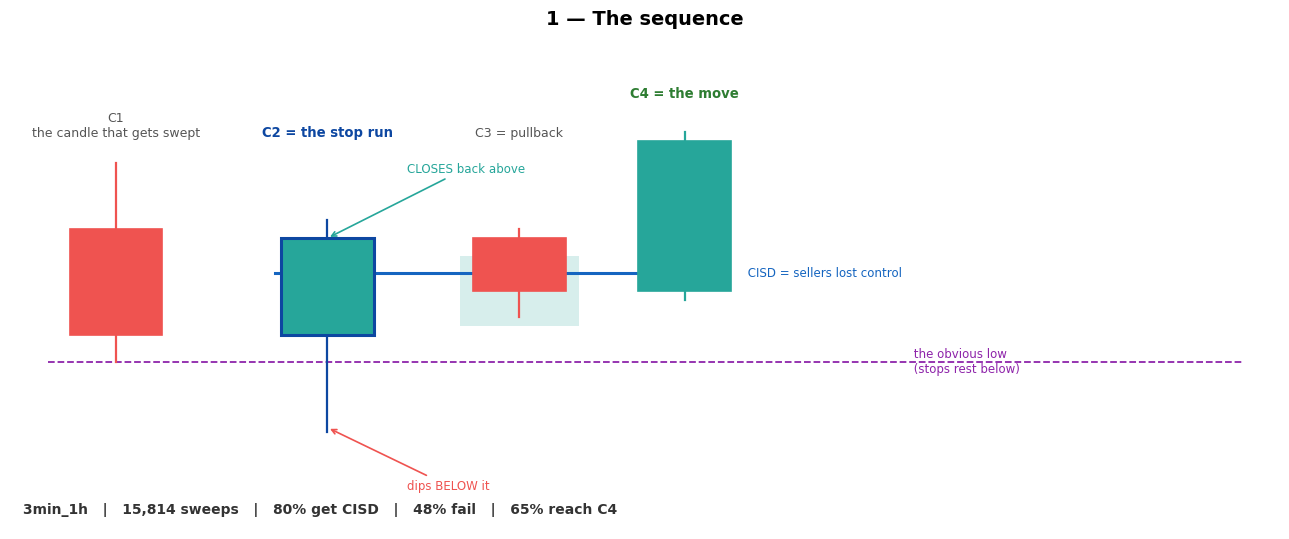

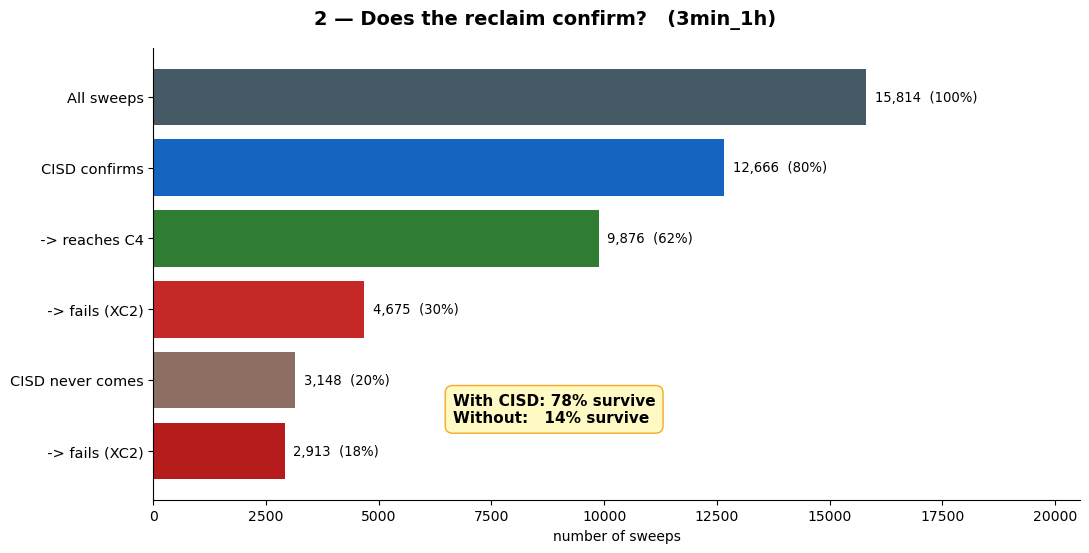

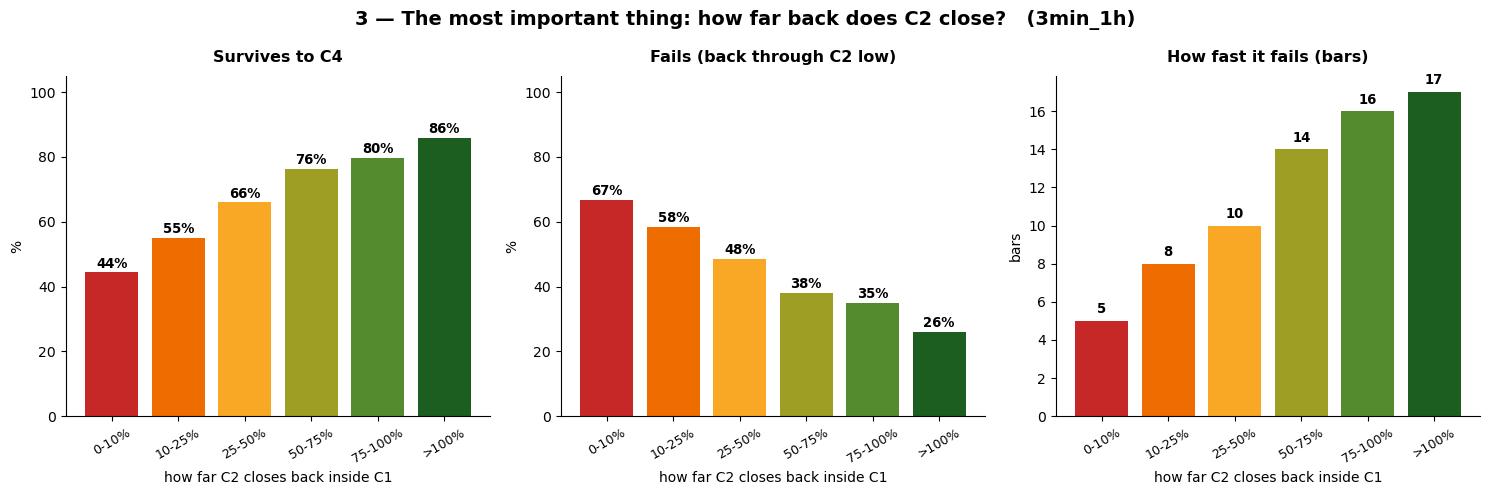

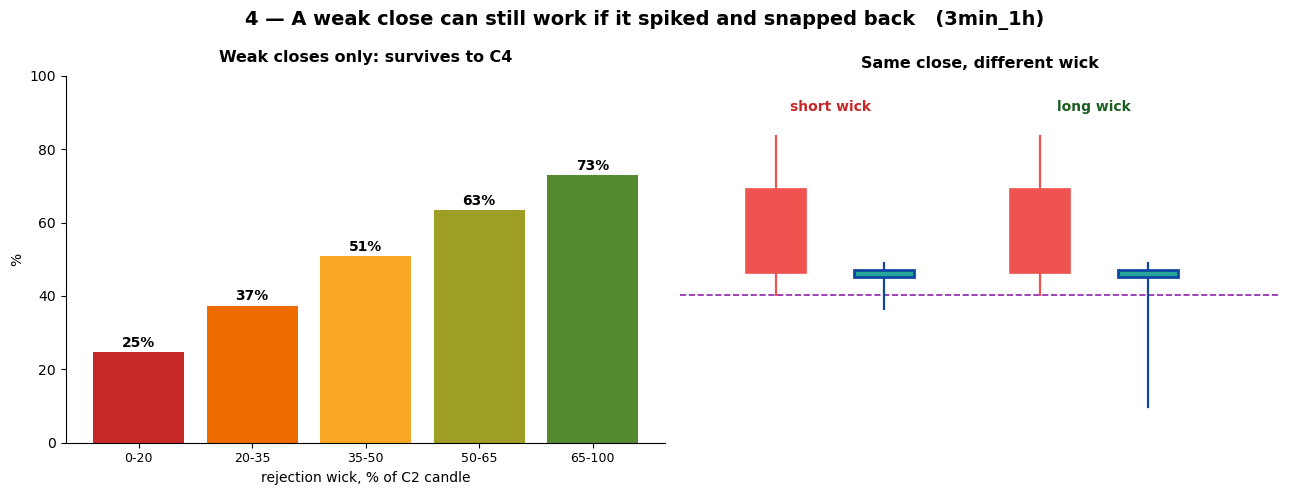

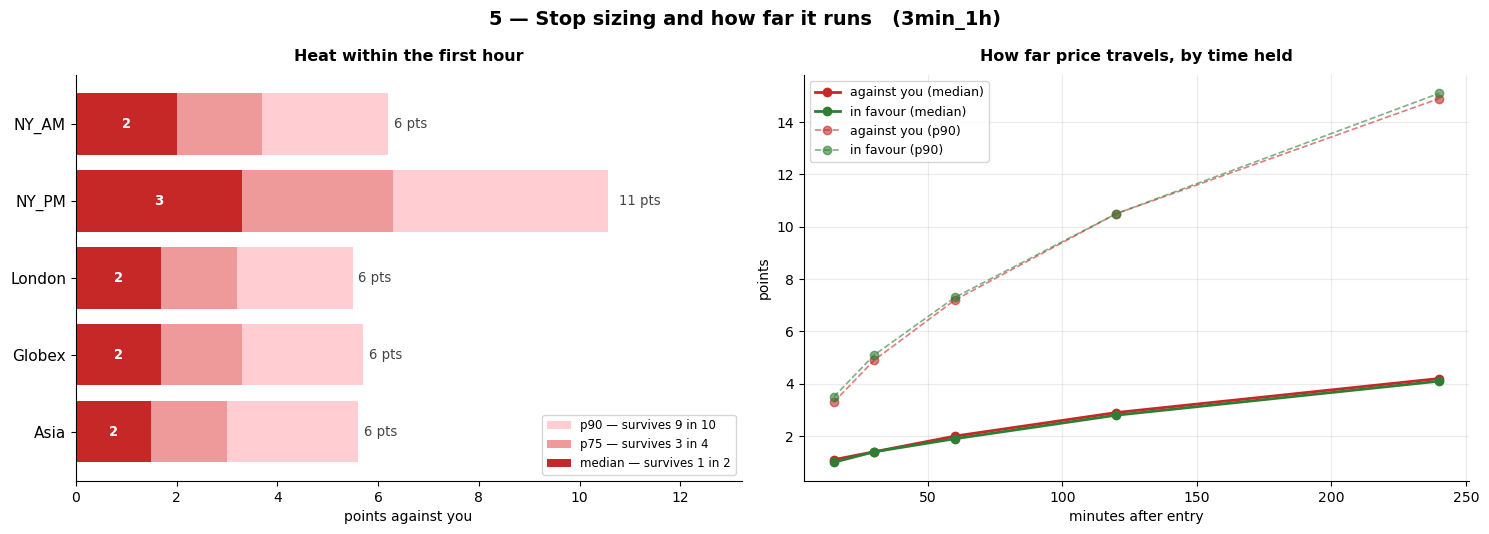

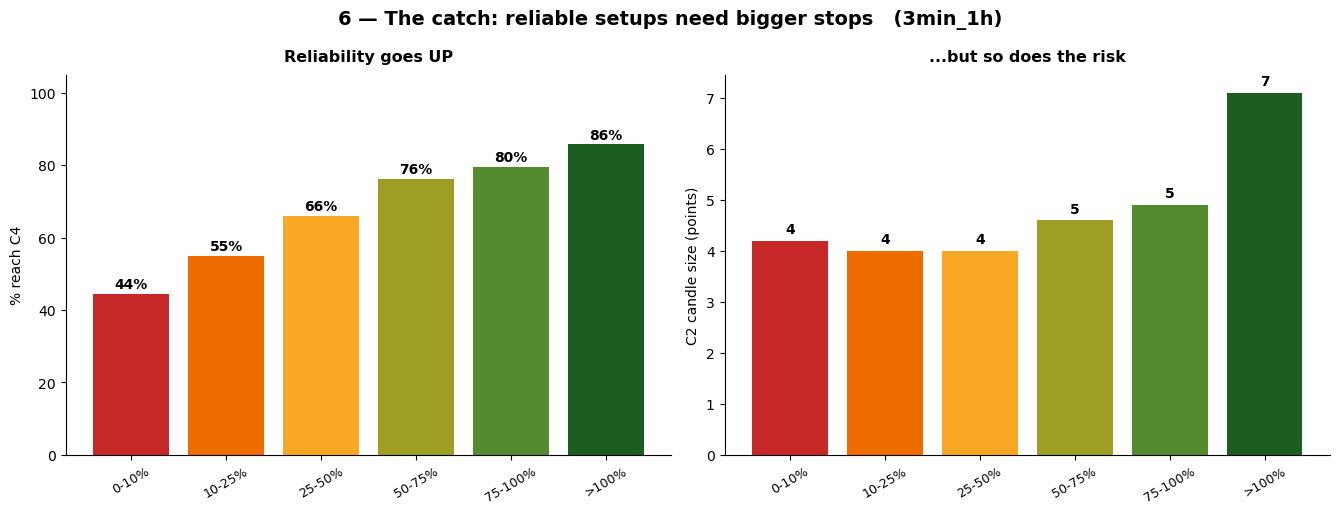

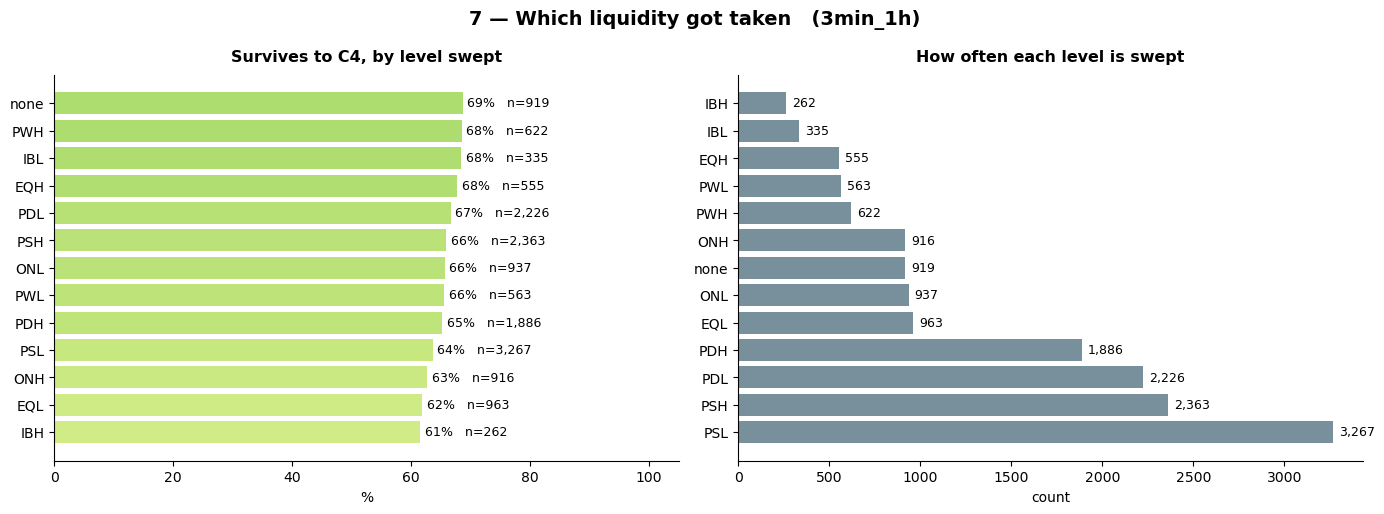

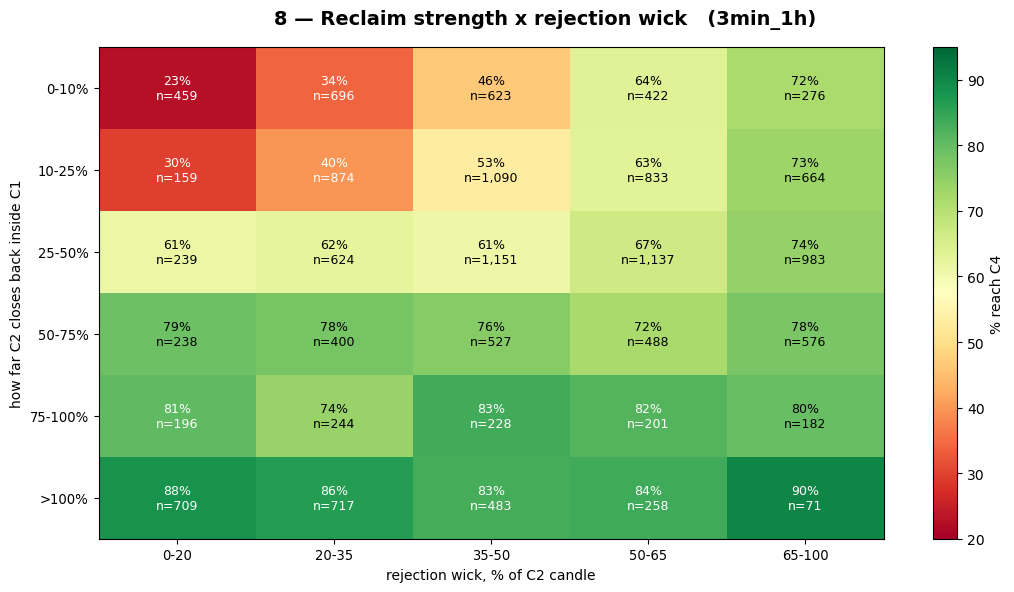

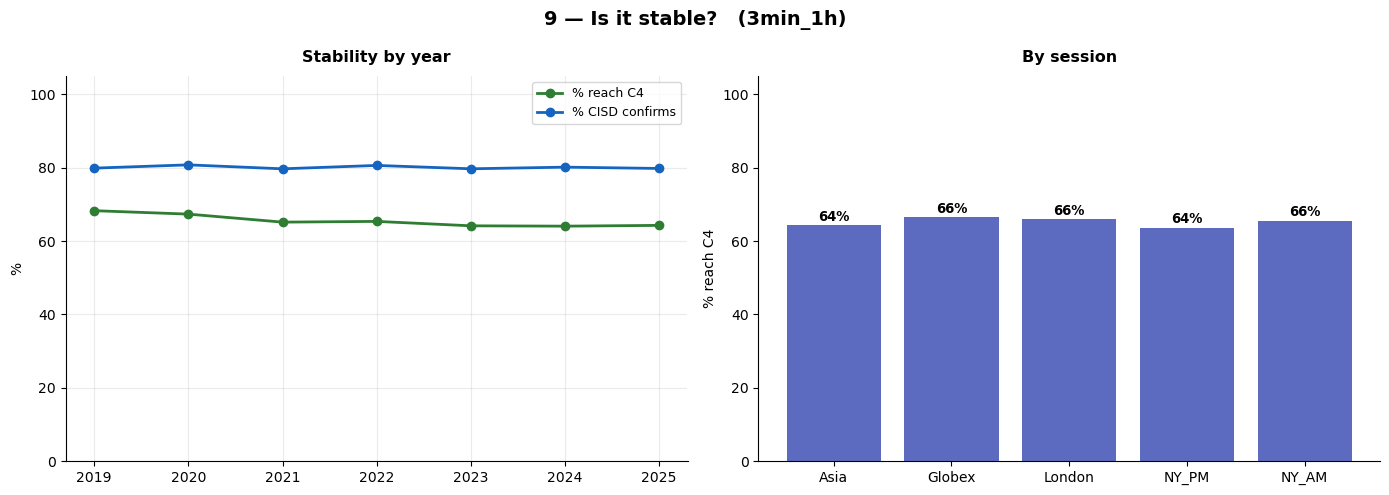

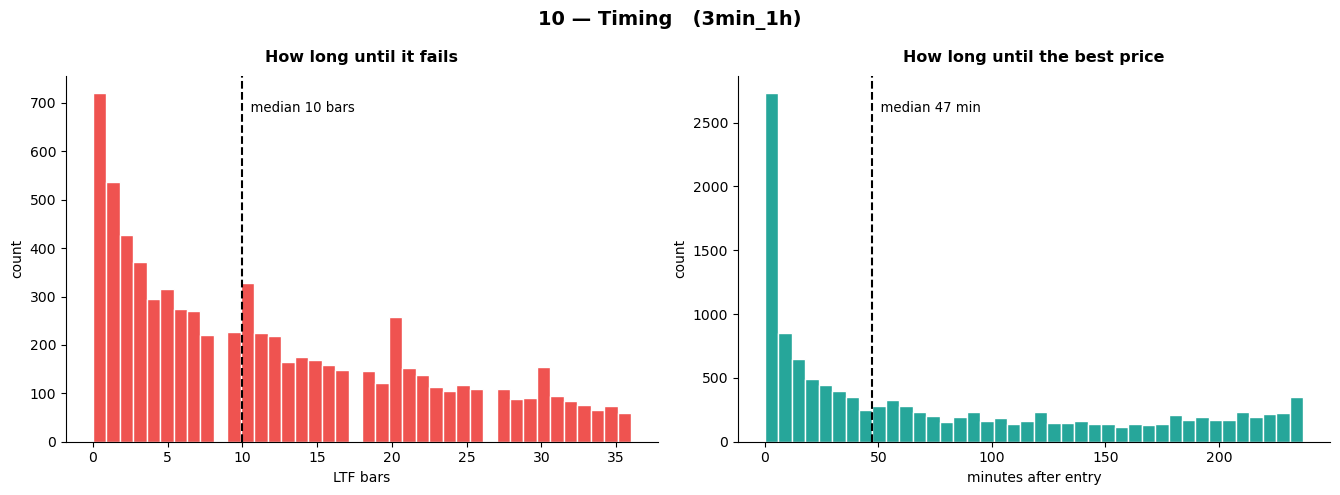


Done — 10 charts. Change CSV_PATH to any other events_*.csv and re-run.


In [5]:
# ═══════════════════════════════════════════════════════════════════════════
#  FRACTAL CHARTS — self-contained. Paste this whole thing into ONE notebook cell.
#  Set CSV_PATH below, run it. Charts appear inline. Nothing else needed.
# ═══════════════════════════════════════════════════════════════════════════

CSV_PATH = r"C:\Users\tammm\NQ and ES analysis\fractal_stats\events_3min_1h.csv"

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mp
%matplotlib inline

UP, DN = '#26a69a', '#ef5350'
SEQ = ['#c62828', '#ef6c00', '#f9a825', '#9e9d24', '#558b2f', '#1b5e20']
SESSION_ORDER = ['Asia', 'Globex', 'London', 'NY_PM', 'NY_AM']
BINS = ['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%']

# ---------- load ----------
d = pd.read_csv(CSV_PATH)
tag = CSV_PATH.replace('\\', '/').split('events_')[-1].replace('.csv', '')
d['c2c_bin'] = pd.cut(d['c2c_in_c1'], [0, 10, 25, 50, 75, 100, 1e9], labels=BINS)
d['sweep_wick_bin'] = pd.cut(d['sweep_wick_pct'], [0, 20, 35, 50, 65, 100],
                             labels=['0-20', '20-35', '35-50', '50-65', '65-100'])
for c in ['xc2', 'reached_c4', 'cisd_confirmed']:
    if d[c].dtype == object:
        d[c] = d[c].astype(str).str.lower().isin(['true', '1', 'yes'])
print(f'{tag}: {len(d):,} sweeps loaded')


def _cd(ax, x, o, h, l, c, w=0.7, edge=None, lw=1.2):
    col = UP if c >= o else DN
    ax.plot([x, x], [l, h], color=edge or col, lw=1.6, zorder=3)
    ax.add_patch(mp.Rectangle((x - w/2, min(o, c)), w, max(abs(c-o), .12),
                              facecolor=col, edgecolor=edge or col, lw=lw, zorder=4))

def _f(ax, t=None, xl=None, yl=None):
    if t: ax.set_title(t, fontsize=11.5, fontweight='bold', pad=10)
    if xl: ax.set_xlabel(xl, fontsize=10)
    if yl: ax.set_ylabel(yl, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)


# ---------- 1. the sequence ----------
fig, ax = plt.subplots(figsize=(13, 5.4))
_cd(ax, 1, 8, 9.5, 5.0, 5.6)
ax.text(1, 10.1, 'C1\nthe candle that gets swept', ha='center', fontsize=9, color='#555')
ax.axhline(5.0, xmin=.03, xmax=.97, color='#8e24aa', ls='--', lw=1.3)
ax.text(7.0, 5.0, ' the obvious low\n (stops rest below)', fontsize=8.5, color='#8e24aa', va='center')
_cd(ax, 2.6, 5.6, 8.2, 3.4, 7.8, edge='#0d47a1', lw=2.2)
ax.annotate('dips BELOW it', xy=(2.6, 3.5), xytext=(3.2, 2.1), fontsize=8.5, color=DN,
            arrowprops=dict(arrowstyle='->', color=DN, lw=1.2))
ax.annotate('CLOSES back above', xy=(2.6, 7.8), xytext=(3.2, 9.3), fontsize=8.5, color=UP,
            arrowprops=dict(arrowstyle='->', color=UP, lw=1.2))
ax.text(2.6, 10.1, 'C2 = the stop run', ha='center', fontsize=9.5, fontweight='bold', color='#0d47a1')
ax.plot([2.2, 5.6], [7.0, 7.0], color='#1565c0', lw=2.2)
ax.text(5.75, 7.0, ' CISD = sellers lost control', fontsize=8.5, color='#1565c0', va='center')
ax.add_patch(mp.Rectangle((3.6, 5.8), .9, 1.6, facecolor='#26a69a', alpha=.18, zorder=0))
_cd(ax, 4.05, 7.8, 8.0, 6.0, 6.6)
ax.text(4.05, 10.1, 'C3 = pullback', ha='center', fontsize=9, color='#555')
_cd(ax, 5.3, 6.6, 10.2, 6.4, 10.0)
ax.text(5.3, 11.0, 'C4 = the move', ha='center', fontsize=9.5, fontweight='bold', color='#2e7d32')
ax.set_xlim(.2, 9.8); ax.set_ylim(1.2, 12.0); ax.axis('off')
ax.text(.3, 1.55, f"{tag}   |   {len(d):,} sweeps   |   {d.cisd_confirmed.mean()*100:.0f}% get CISD"
        f"   |   {d.xc2.mean()*100:.0f}% fail   |   {d.reached_c4.mean()*100:.0f}% reach C4",
        fontsize=10, color='#333', fontweight='bold')
fig.suptitle('1 — The sequence', fontsize=14, fontweight='bold', y=.99)
plt.tight_layout(); plt.show()


# ---------- 2. funnel ----------
cis, noc = d[d.cisd_confirmed], d[~d.cisd_confirmed]
fig, ax = plt.subplots(figsize=(11, 5.6))
bars = [('All sweeps', len(d), '#455a64'), ('CISD confirms', len(cis), '#1565c0'),
        ('  -> reaches C4', int(cis.reached_c4.sum()), '#2e7d32'),
        ('  -> fails (XC2)', int(cis.xc2.sum()), '#c62828'),
        ('CISD never comes', len(noc), '#8d6e63'),
        ('  -> fails (XC2)', int(noc.xc2.sum()), '#b71c1c')]
y = np.arange(len(bars))[::-1]
ax.barh(y, [b[1] for b in bars], color=[b[2] for b in bars])
for yy, (lab, v, _) in zip(y, bars):
    ax.text(v + len(d)*.012, yy, f'{v:,}  ({v/len(d)*100:.0f}%)', va='center', fontsize=9.5)
ax.set_yticks(y); ax.set_yticklabels([b[0] for b in bars], fontsize=10.5)
ax.set_xlim(0, len(d)*1.3); _f(ax, xl='number of sweeps')
if len(cis) and len(noc):
    ax.text(len(d)*.42, .4, f"With CISD: {cis.reached_c4.mean()*100:.0f}% survive\n"
            f"Without:   {noc.reached_c4.mean()*100:.0f}% survive", fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', fc='#fff9c4', ec='#f9a825'))
fig.suptitle(f'2 — Does the reclaim confirm?   ({tag})', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


# ---------- 3. reclaim strength ----------
g = d.groupby('c2c_bin', observed=True).agg(
    c4=('reached_c4', lambda x: x.mean()*100), fail=('xc2', lambda x: x.mean()*100),
    bars=('xc2_bars', 'median')).reindex(BINS).dropna(how='all')
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
x = np.arange(len(g)); cols = SEQ[:len(g)]
for ax, col, ttl, ylim in [(axes[0], 'c4', 'Survives to C4', 105),
                           (axes[1], 'fail', 'Fails (back through C2 low)', 105),
                           (axes[2], 'bars', 'How fast it fails (bars)', None)]:
    ax.bar(x, g[col], color=cols)
    for i, v in enumerate(g[col]):
        ax.text(i, v + (1.5 if ylim else .4), f'{v:.0f}' + ('%' if ylim else ''),
                ha='center', fontweight='bold', fontsize=9.5)
    _f(ax, ttl, 'how far C2 closes back inside C1', '%' if ylim else 'bars')
    if ylim: ax.set_ylim(0, ylim)
    ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=30, fontsize=9)
fig.suptitle(f'3 — The most important thing: how far back does C2 close?   ({tag})',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


# ---------- 4. wick rescue ----------
weak = d[d.c2c_bin.isin(['0-10%', '10-25%'])]
if len(weak) > 100:
    g = weak.groupby('sweep_wick_bin', observed=True).agg(
        c4=('reached_c4', lambda x: x.mean()*100)).dropna(how='all')
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
    x = np.arange(len(g))
    a1.bar(x, g.c4, color=SEQ[:len(g)])
    for i, v in enumerate(g.c4): a1.text(i, v+1.5, f'{v:.0f}%', ha='center', fontweight='bold')
    _f(a1, 'Weak closes only: survives to C4', 'rejection wick, % of C2 candle', '%')
    a1.set_ylim(0, 100); a1.set_xticks(x); a1.set_xticklabels(g.index, fontsize=9)
    for i, (lab, lp, cl) in enumerate(zip(['short wick', 'long wick'], [4.6, 1.8], ['#c62828', '#1b5e20'])):
        xo = i*2.2
        _cd(a2, 1+xo, 8, 9.5, 5.0, 5.6, w=.5); _cd(a2, 1.9+xo, 5.5, 5.9, lp, 5.7, w=.5, edge='#0d47a1', lw=2)
        a2.text(1.45+xo, 10.2, lab, ha='center', fontsize=10, fontweight='bold', color=cl)
    a2.axhline(5.0, color='#8e24aa', ls='--', lw=1.2)
    a2.set_xlim(.2, 5.2); a2.set_ylim(.8, 11.2); a2.axis('off')
    a2.set_title('Same close, different wick', fontsize=11.5, fontweight='bold')
    fig.suptitle(f'4 — A weak close can still work if it spiked and snapped back   ({tag})',
                 fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()


# ---------- 5. stops ----------
pre = 'ci_' if 'ci_mae_60m' in d.columns else 'c2_'
sub = d[d[f'{pre}mae_60m'].notna()]
if len(sub) > 100:
    g = sub.groupby('Session').agg(med=(f'{pre}mae_60m', 'median'),
        p75=(f'{pre}mae_60m', lambda x: x.quantile(.75)),
        p90=(f'{pre}mae_60m', lambda x: x.quantile(.9)))
    g = g.reindex([s for s in SESSION_ORDER if s in g.index]).dropna(how='all')
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.4))
    y = np.arange(len(g))
    a1.barh(y, g.p90, color='#ffcdd2', label='p90 — survives 9 in 10')
    a1.barh(y, g.p75, color='#ef9a9a', label='p75 — survives 3 in 4')
    a1.barh(y, g.med, color='#c62828', label='median — survives 1 in 2')
    for i, (m, b) in enumerate(zip(g.med, g.p90)):
        a1.text(m/2, i, f'{m:.0f}', va='center', ha='center', color='white', fontweight='bold', fontsize=9.5)
        a1.text(b*1.02, i, f'{b:.0f} pts', va='center', fontsize=9.5, color='#444')
    a1.set_yticks(y); a1.set_yticklabels(g.index, fontsize=11)
    _f(a1, 'Heat within the first hour', 'points against you'); a1.legend(fontsize=8.5, loc='lower right')
    a1.set_xlim(0, g.p90.max()*1.25)
    hs = [15, 30, 60, 120, 240]
    hh = [h for h in hs if f'{pre}mae_{h}m' in sub.columns]
    a2.plot(hh, [sub[f'{pre}mae_{h}m'].median() for h in hh], 'o-', color='#c62828', lw=2, label='against you (median)')
    a2.plot(hh, [sub[f'{pre}mfe_{h}m'].median() for h in hh], 'o-', color='#2e7d32', lw=2, label='in favour (median)')
    a2.plot(hh, [sub[f'{pre}mae_{h}m'].quantile(.9) for h in hh], 'o--', color='#c62828', lw=1.2, alpha=.6, label='against you (p90)')
    a2.plot(hh, [sub[f'{pre}mfe_{h}m'].quantile(.9) for h in hh], 'o--', color='#2e7d32', lw=1.2, alpha=.6, label='in favour (p90)')
    _f(a2, 'How far price travels, by time held', 'minutes after entry', 'points')
    a2.legend(fontsize=9); a2.grid(alpha=.25)
    fig.suptitle(f'5 — Stop sizing and how far it runs   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()


# ---------- 6. trade-off ----------
g = d.groupby('c2c_bin', observed=True).agg(c4=('reached_c4', lambda x: x.mean()*100),
    rng=('c2_range', 'median')).reindex(BINS).dropna(how='all')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
x = np.arange(len(g)); cols = SEQ[:len(g)]
a1.bar(x, g.c4, color=cols)
for i, v in enumerate(g.c4): a1.text(i, v+1.5, f'{v:.0f}%', ha='center', fontweight='bold')
_f(a1, 'Reliability goes UP', None, '% reach C4'); a1.set_ylim(0, 105)
a2.bar(x, g.rng, color=cols)
for i, v in enumerate(g.rng): a2.text(i, v+g.rng.max()*.02, f'{v:.0f}', ha='center', fontweight='bold')
_f(a2, '...but so does the risk', None, 'C2 candle size (points)')
for a in (a1, a2):
    a.set_xticks(x); a.set_xticklabels(g.index, rotation=30, fontsize=9)
fig.suptitle(f'6 — The catch: reliable setups need bigger stops   ({tag})', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


# ---------- 7. liquidity ----------
g = d.groupby('liq_primary', observed=True).agg(n=('xc2', 'size'),
    c4=('reached_c4', lambda x: x.mean()*100)).query('n >= 100').sort_values('c4')
if len(g) > 1:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2))
    y = np.arange(len(g))
    a1.barh(y, g.c4, color=plt.cm.RdYlGn(g.c4/100))
    for i, (v, n) in enumerate(zip(g.c4, g.n)): a1.text(v+.8, i, f'{v:.0f}%   n={n:,}', va='center', fontsize=9)
    a1.set_yticks(y); a1.set_yticklabels(g.index, fontsize=10)
    _f(a1, 'Survives to C4, by level swept', '%'); a1.set_xlim(0, 105)
    mix = d.liq_primary.value_counts()
    a2.barh(np.arange(len(mix)), mix.values, color='#78909c')
    a2.set_yticks(np.arange(len(mix))); a2.set_yticklabels(mix.index, fontsize=10)
    for i, v in enumerate(mix.values): a2.text(v+mix.max()*.01, i, f'{v:,}', va='center', fontsize=9)
    _f(a2, 'How often each level is swept', 'count')
    fig.suptitle(f'7 — Which liquidity got taken   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()


# ---------- 8. heatmap ----------
p = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin', values='reached_c4',
                  aggfunc='mean', observed=True)*100
n = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin', values='reached_c4',
                  aggfunc='size', observed=True)
if not p.empty:
    fig, ax = plt.subplots(figsize=(11, 6))
    im = ax.imshow(p.values, cmap='RdYlGn', vmin=20, vmax=95, aspect='auto')
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            if np.isfinite(v):
                nn = n.values[i, j]
                ax.text(j, i, f'{v:.0f}%\nn={int(nn):,}', ha='center', va='center', fontsize=9,
                        color='white' if (v < 40 or v > 80) else 'black')
    ax.set_xticks(range(p.shape[1])); ax.set_xticklabels(p.columns, fontsize=9.5)
    ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index, fontsize=9.5)
    ax.set_xlabel('rejection wick, % of C2 candle', fontsize=10)
    ax.set_ylabel('how far C2 closes back inside C1', fontsize=10)
    plt.colorbar(im, ax=ax, label='% reach C4')
    fig.suptitle(f'8 — Reclaim strength x rejection wick   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()


# ---------- 9. stability ----------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
gy = d.groupby('year').agg(n=('xc2', 'size'), c4=('reached_c4', lambda x: x.mean()*100),
                           cisd=('cisd_confirmed', lambda x: x.mean()*100))
gy = gy[gy.n >= 100]
a1.plot(gy.index, gy.c4, 'o-', lw=2, color='#2e7d32', label='% reach C4')
a1.plot(gy.index, gy.cisd, 'o-', lw=2, color='#1565c0', label='% CISD confirms')
_f(a1, 'Stability by year', None, '%'); a1.set_ylim(0, 105); a1.legend(fontsize=9); a1.grid(alpha=.25)
gs = d.groupby('Session').agg(c4=('reached_c4', lambda x: x.mean()*100))
gs = gs.reindex([s for s in SESSION_ORDER if s in gs.index]).dropna(how='all')
a2.bar(np.arange(len(gs)), gs.c4, color='#5c6bc0')
for i, v in enumerate(gs.c4): a2.text(i, v+1.2, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=9.5)
a2.set_xticks(np.arange(len(gs))); a2.set_xticklabels(gs.index, fontsize=10)
_f(a2, 'By session', None, '% reach C4'); a2.set_ylim(0, 105)
fig.suptitle(f'9 — Is it stable?   ({tag})', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


# ---------- 10. timing ----------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5))
x = d.xc2_bars.dropna(); x = x[x <= x.quantile(.97)]
if len(x):
    a1.hist(x, bins=40, color='#ef5350', edgecolor='white')
    a1.axvline(x.median(), color='black', ls='--', lw=1.5)
    a1.text(x.median(), a1.get_ylim()[1]*.9, f'  median {x.median():.0f} bars', fontsize=9.5)
_f(a1, 'How long until it fails', 'LTF bars', 'count')
c = f'{pre}bars_to_mfe'
if c in d.columns:
    yv = d[c].dropna(); yv = yv[yv <= yv.quantile(.97)]
    if len(yv):
        a2.hist(yv, bins=40, color='#26a69a', edgecolor='white')
        a2.axvline(yv.median(), color='black', ls='--', lw=1.5)
        a2.text(yv.median(), a2.get_ylim()[1]*.9, f'  median {yv.median():.0f} min', fontsize=9.5)
_f(a2, 'How long until the best price', 'minutes after entry', 'count')
fig.suptitle(f'10 — Timing   ({tag})', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print('\nDone — 10 charts. Change CSV_PATH to any other events_*.csv and re-run.')

In [6]:
# ═══════════════════════════════════════════════════════════════════════════
#  FRACTAL SUMMARY TABLES — self-contained. Paste into ONE notebook cell.
#
#  PART A  tables for a single pairing   (set CSV_PATH)
#  PART B  one comparison table across ALL pairings (set FOLDER)
#
#  Uses the events_*.csv files you already generated. Nothing to install.
# ═══════════════════════════════════════════════════════════════════════════

CSV_PATH = r"C:\Users\tammm\NQ and ES analysis\fractal_stats\events_3min_1h.csv"
FOLDER   = r"C:\Users\tammm\NQ and ES analysis\fractal_stats"

import numpy as np, pandas as pd, glob, os
from IPython.display import display, Markdown

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 60)

BINS = ['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%']
WICK = ['0-20', '20-35', '35-50', '50-65', '65-100']
SESSION_ORDER = ['Asia', 'Globex', 'London', 'NY_PM', 'NY_AM']


def load(path):
    d = pd.read_csv(path)
    d['c2c_bin'] = pd.cut(d['c2c_in_c1'], [0, 10, 25, 50, 75, 100, 1e9], labels=BINS)
    d['sweep_wick_bin'] = pd.cut(d['sweep_wick_pct'], [0, 20, 35, 50, 65, 100], labels=WICK)
    d['body_bin'] = pd.cut(d['c2_body_pct'], [0, 10, 20, 35, 50, 70, 100],
                           labels=['0-10 doji', '10-20', '20-35', '35-50', '50-70', '70-100'])
    for c in ['xc2', 'reached_c4', 'cisd_confirmed', 'cisd_early', 'is_bull',
              'eq_reached', 'closed_beyond_c1', 'close_with_reclaim']:
        if c in d.columns and d[c].dtype == object:
            d[c] = d[c].astype(str).str.lower().isin(['true', '1', 'yes'])
    return d


def h(txt):
    display(Markdown(f'### {txt}'))


def pct(s):
    return round(s.mean() * 100, 1)


# ═══════════════════════════════════════════════════════════════════════════
# PART A — one pairing
# ═══════════════════════════════════════════════════════════════════════════
d = load(CSV_PATH)
tag = CSV_PATH.replace('\\', '/').split('events_')[-1].replace('.csv', '')
pre = 'ci_' if 'ci_mae_60m' in d.columns else 'c2_'
anchor = 'CISD confirmation' if pre == 'ci_' else 'C2 close'

display(Markdown(f'# {tag}  —  {len(d):,} sweeps\n'
                 f'*excursions measured from **{anchor}***'))

# --- 1 headline
h('1. Headline')
cis, noc = d[d.cisd_confirmed], d[~d.cisd_confirmed]
t1 = pd.DataFrame([
    dict(measure='Sweeps (C2 events)', value=f'{len(d):,}'),
    dict(measure='CISD confirms', value=f'{pct(d.cisd_confirmed)}%'),
    dict(measure='  of those, reach C4', value=f'{pct(cis.reached_c4)}%' if len(cis) else '-'),
    dict(measure='  of those, fail', value=f'{pct(cis.xc2)}%' if len(cis) else '-'),
    dict(measure='CISD never confirms', value=f'{pct(~d.cisd_confirmed)}%'),
    dict(measure='  of those, fail', value=f'{pct(noc.xc2)}%' if len(noc) else '-'),
    dict(measure='Overall fail rate (XC2)', value=f'{pct(d.xc2)}%'),
    dict(measure='Overall reach C4', value=f'{pct(d.reached_c4)}%'),
    dict(measure='Median bars to failure', value=f'{d.xc2_bars.median():.0f}'),
    dict(measure='Equilibrium reached', value=f'{pct(d.eq_reached)}%'),
])
display(t1)

# --- 2 reclaim strength (the main table)
h('2. By reclaim strength — how far C2 closes back inside C1')
t2 = d.groupby('c2c_bin', observed=True).agg(
    n=('xc2', 'size'),
    share_pct=('xc2', lambda x: round(len(x) / len(d) * 100, 1)),
    cisd_pct=('cisd_confirmed', pct),
    reach_c4_pct=('reached_c4', pct),
    fail_pct=('xc2', pct),
    med_bars_to_fail=('xc2_bars', 'median'),
    med_c2_range_pts=('c2_range', 'median'),
).reindex(BINS).dropna(how='all')
if f'{pre}mae_60m' in d.columns:
    extra = d.groupby('c2c_bin', observed=True).agg(
        med_mae_60m=(f'{pre}mae_60m', 'median'),
        p90_mae_60m=(f'{pre}mae_60m', lambda x: x.quantile(.9))).reindex(BINS)
    t2 = t2.join(extra)
display(t2.round(1))

# --- 3 wick rescue
h('3. Weak closes only (0-25%) — does a long rejection wick help?')
weak = d[d.c2c_bin.isin(['0-10%', '10-25%'])]
t3 = weak.groupby('sweep_wick_bin', observed=True).agg(
    n=('xc2', 'size'), reach_c4_pct=('reached_c4', pct), fail_pct=('xc2', pct),
    med_bars_to_fail=('xc2_bars', 'median')).reindex(WICK).dropna(how='all')
display(t3.round(1))

# --- 4 two-way
h('4. Reclaim strength x rejection wick  (% reaching C4, n in brackets)')
p = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin', values='reached_c4',
                  aggfunc='mean', observed=True) * 100
nn = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin', values='reached_c4',
                   aggfunc='size', observed=True)
combo = p.round(0).astype('Int64').astype(str) + '%  (' + nn.astype('Int64').astype(str) + ')'
display(combo.reindex(BINS))

# --- 5 stops by session
if f'{pre}mae_60m' in d.columns:
    h(f'5. Stop sizing — adverse move from {anchor} (points)')
    rows = []
    for s in SESSION_ORDER:
        g = d[d.Session == s]
        if len(g) < 50:
            continue
        r = dict(session=s, n=len(g))
        for hz in [15, 30, 60]:
            c = f'{pre}mae_{hz}m'
            if c in g.columns:
                r[f'{hz}m_med'] = round(g[c].median(), 1)
                r[f'{hz}m_p90'] = round(g[c].quantile(.9), 1)
        rows.append(r)
    display(pd.DataFrame(rows))

    # --- 6 MAE/MFE by horizon
    h(f'6. How far price travels from {anchor}')
    rows = []
    for hz in [15, 30, 60, 120, 240]:
        ca, cf = f'{pre}mae_{hz}m', f'{pre}mfe_{hz}m'
        if ca in d.columns:
            rows.append(dict(horizon=f'{hz}m',
                             against_med=round(d[ca].median(), 1),
                             against_p75=round(d[ca].quantile(.75), 1),
                             against_p90=round(d[ca].quantile(.9), 1),
                             favour_med=round(d[cf].median(), 1),
                             favour_p75=round(d[cf].quantile(.75), 1),
                             favour_p90=round(d[cf].quantile(.9), 1)))
    display(pd.DataFrame(rows))

# --- 7 liquidity
h('7. By liquidity swept')
t7 = d.groupby('liq_primary', observed=True).agg(
    n=('xc2', 'size'), reach_c4_pct=('reached_c4', pct), fail_pct=('xc2', pct),
    med_bars_to_fail=('xc2_bars', 'median')).query('n >= 100').sort_values('reach_c4_pct',
                                                                          ascending=False)
display(t7.round(1))

# --- 8 context
h('8. By session / direction / year')
c1 = d.groupby('Session').agg(n=('xc2', 'size'), reach_c4_pct=('reached_c4', pct),
                              fail_pct=('xc2', pct))
c1 = c1.reindex([s for s in SESSION_ORDER if s in c1.index])
c2t = d.groupby(d.is_bull.map({True: 'bullish (swept a low)', False: 'bearish (swept a high)'})).agg(
    n=('xc2', 'size'), reach_c4_pct=('reached_c4', pct), fail_pct=('xc2', pct))
c3 = d.groupby('year').agg(n=('xc2', 'size'), reach_c4_pct=('reached_c4', pct),
                           cisd_pct=('cisd_confirmed', pct))
display(c1.round(1)); display(c2t.round(1)); display(c3[c3.n >= 100].round(1))


# ═══════════════════════════════════════════════════════════════════════════
# PART B — all pairings side by side
# ═══════════════════════════════════════════════════════════════════════════
files = sorted(glob.glob(os.path.join(FOLDER, 'events_*.csv')))
if files:
    display(Markdown('---\n# All pairings compared'))
    rows, strength_rows, stop_rows = [], [], []
    for f in files:
        t = os.path.basename(f).replace('events_', '').replace('.csv', '')
        try:
            x = load(f)
        except Exception as e:
            print(f'{t}: {e}'); continue
        p_ = 'ci_' if 'ci_mae_60m' in x.columns else 'c2_'
        cis_ = x[x.cisd_confirmed]; noc_ = x[~x.cisd_confirmed]
        rows.append(dict(pairing=t, n=len(x),
                         cisd_pct=pct(x.cisd_confirmed),
                         early_cisd_pct=pct(x.cisd_early) if 'cisd_early' in x else np.nan,
                         fail_pct=pct(x.xc2),
                         reach_c4_pct=pct(x.reached_c4),
                         c4_if_cisd=pct(cis_.reached_c4) if len(cis_) else np.nan,
                         c4_if_no_cisd=pct(noc_.reached_c4) if len(noc_) else np.nan,
                         med_bars_to_fail=x.xc2_bars.median(),
                         med_mae_60m=x[f'{p_}mae_60m'].median() if f'{p_}mae_60m' in x else np.nan))
        # reach-C4 by strength bin, one row per pairing
        g = x.groupby('c2c_bin', observed=True)['reached_c4'].mean().reindex(BINS) * 100
        strength_rows.append(pd.Series(g.values, index=BINS, name=t))
        # stop sizing by session
        if f'{p_}mae_60m' in x.columns:
            gs = x.groupby('Session')[f'{p_}mae_60m'].quantile(.9)
            stop_rows.append(pd.Series(gs, name=t))

    h('Base rates by pairing')
    display(pd.DataFrame(rows).round(1).to_string(index=False))

    h('% reaching C4, by reclaim strength — every pairing')
    display(pd.DataFrame(strength_rows).round(1))

    if stop_rows:
        h('p90 adverse move within 60 min (points) — every pairing x session')
        st = pd.DataFrame(stop_rows)
        st = st[[c for c in SESSION_ORDER if c in st.columns]]
        display(st.round(1))

    print('\nRead: the strength table should rise left-to-right in EVERY row.')
    print('If it does, the pattern holds across all timeframe pairings.')

# 3min_1h  —  15,814 sweeps
*excursions measured from **CISD confirmation***

### 1. Headline

,measure,value
0,Sweeps (C2 events),"15,814"
1,CISD confirms,80.1%
2,"of those, reach C4",78.0%
3,"of those, fail",36.9%
4,CISD never confirms,19.9%
5,"of those, fail",92.5%
6,Overall fail rate (XC2),48.0%
7,Overall reach C4,65.3%
8,Median bars to failure,10
9,Equilibrium reached,82.6%


### 2. By reclaim strength — how far C2 closes back inside C1

,n,share_pct,cisd_pct,reach_c4_pct,fail_pct,med_bars_to_fail,med_c2_range_pts,med_mae_60m,p90_mae_60m
c2c_bin,,,,,,,,,
0-10%,2481,15.7,57.8,44.4,66.7,5.0,4.2,2.0,7.0
10-25%,3626,22.9,69.6,55.0,58.3,8.0,4.0,1.9,6.3
25-50%,4146,26.2,82.6,66.0,48.4,10.0,4.0,1.8,6.8
50-75%,2236,14.1,92.3,76.3,38.1,14.0,4.6,1.9,6.9
75-100%,1055,6.7,94.9,79.6,35.0,16.0,4.9,2.0,6.7
>100%,2254,14.3,98.0,85.8,25.9,17.0,7.1,2.3,9.4


### 3. Weak closes only (0-25%) — does a long rejection wick help?

... (17 outputs left out)

,0-10%,10-25%,25-50%,50-75%,75-100%,>100%
1min_15min,45.9,55.9,68.4,79.8,85.6,91.0
1min_1D,46.6,57.9,70.4,77.9,81.0,79.8
1min_1h,44.4,55.0,66.0,76.3,79.6,85.8
1min_2h,45.8,54.8,64.2,72.7,76.0,85.0
1min_30min,45.4,54.8,67.2,77.3,82.7,90.1
1min_4h,46.7,57.8,62.1,70.8,73.5,85.7
2min_15min,45.8,55.3,67.8,79.2,85.2,90.6
2min_1D,46.6,57.9,70.4,77.9,81.0,79.8
2min_1h,44.4,55.0,66.0,76.3,79.6,85.8
2min_2h,45.8,54.8,64.2,72.7,76.0,85.0


### p90 adverse move within 60 min (points) — every pairing x session

Session,Asia,Globex,London,NY_PM,NY_AM
1min_15min,5.8,5.9,5.9,10.5,6.9
1min_1D,6.2,6.3,4.0,NaN,7.7
1min_1h,5.6,6.0,5.7,10.8,6.3
1min_2h,5.5,6.1,5.5,9.5,6.3
1min_30min,5.4,5.9,5.7,10.2,6.6
1min_4h,6.4,NaN,3.9,8.4,6.7
2min_15min,5.6,5.6,5.7,10.4,6.8
2min_1D,8.2,6.0,4.0,4.2,NaN
2min_1h,5.6,5.7,5.5,10.7,6.4
2min_2h,5.5,6.1,5.3,9.4,6.2



Read: the strength table should rise left-to-right in EVERY row.
If it does, the pattern holds across all timeframe pairings.


In [7]:
# ═══════════════════════════════════════════════════════════════════════════
#  BATCH RUNNER (hardened) — writes charts + summary for every pairing.
#  Fixes the silent-failure modes: OneDrive Desktop redirect, empty input,
#  and no verification that anything was actually written.
# ═══════════════════════════════════════════════════════════════════════════

import os, glob
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mp

OUT_DIR = r"C:\Users\tammm\NQ and ES analysis\fractal_stats"

# ---- resolve the REAL Desktop (OneDrive often hijacks it) -----------------
def find_desktop():
    home = os.path.expanduser('~')
    for c in [os.path.join(home, 'OneDrive', 'Desktop'),
              os.path.join(home, 'OneDrive - Personal', 'Desktop'),
              os.path.join(home, 'Desktop')]:
        if os.path.isdir(c):
            return c
    return home

CHART_DIR = os.path.join(find_desktop(), 'fractal_charts')
os.makedirs(CHART_DIR, exist_ok=True)
print('Writing charts to:', os.path.abspath(CHART_DIR))

# ---- fail loudly if there is nothing to read -----------------------------
files = sorted(glob.glob(os.path.join(OUT_DIR, 'events_*.csv')))
if not files:
    raise FileNotFoundError(
        f'No events_*.csv in {OUT_DIR}\n'
        f'Contents: {os.listdir(OUT_DIR)[:20] if os.path.isdir(OUT_DIR) else "FOLDER DOES NOT EXIST"}\n'
        f'Run the main descriptive script first, with SAVE_EVENT_CSV = True.')
print(f'Found {len(files)} pairing CSVs\n')

UP, DN = '#26a69a', '#ef5350'
SEQ = ['#c62828', '#ef6c00', '#f9a825', '#9e9d24', '#558b2f', '#1b5e20']
SESSION_ORDER = ['Asia', 'Globex', 'London', 'NY_PM', 'NY_AM']
BINS = ['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%']
WICK = ['0-20', '20-35', '35-50', '50-65', '65-100']


def load(path):
    d = pd.read_csv(path)
    d['c2c_bin'] = pd.cut(d['c2c_in_c1'], [0, 10, 25, 50, 75, 100, 1e9], labels=BINS)
    d['sweep_wick_bin'] = pd.cut(d['sweep_wick_pct'], [0, 20, 35, 50, 65, 100], labels=WICK)
    for c in ['xc2', 'reached_c4', 'cisd_confirmed', 'cisd_early', 'is_bull']:
        if c in d.columns and d[c].dtype == object:
            d[c] = d[c].astype(str).str.lower().isin(['true', '1', 'yes'])
    return d


def _f(ax, t=None, xl=None, yl=None):
    if t: ax.set_title(t, fontsize=11.5, fontweight='bold', pad=10)
    if xl: ax.set_xlabel(xl, fontsize=10)
    if yl: ax.set_ylabel(yl, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)


def make_charts(d, tag, outdir):
    made = []

    # 1 reclaim strength
    g = d.groupby('c2c_bin', observed=True).agg(
        c4=('reached_c4', lambda x: x.mean() * 100),
        fail=('xc2', lambda x: x.mean() * 100),
        bars=('xc2_bars', 'median')).reindex(BINS).dropna(how='all')
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    x = np.arange(len(g)); cols = SEQ[:len(g)]
    for ax, col, ttl, ylim in [(axes[0], 'c4', 'Survives to C4', 105),
                               (axes[1], 'fail', 'Fails (back through C2 low)', 105),
                               (axes[2], 'bars', 'How fast it fails (bars)', None)]:
        ax.bar(x, g[col], color=cols)
        for i, v in enumerate(g[col]):
            ax.text(i, v + (1.5 if ylim else .4), f'{v:.0f}' + ('%' if ylim else ''),
                    ha='center', fontweight='bold', fontsize=9.5)
        _f(ax, ttl, 'reclaim strength', '%' if ylim else 'bars')
        if ylim: ax.set_ylim(0, ylim)
        ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=30, fontsize=9)
    fig.suptitle(f'Reclaim strength -> outcome   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    p = os.path.join(outdir, f'{tag}_01_reclaim_strength.png')
    fig.savefig(p, dpi=130, bbox_inches='tight'); plt.close(fig); made.append(p)

    # 2 funnel
    cis, noc = d[d.cisd_confirmed], d[~d.cisd_confirmed]
    fig, ax = plt.subplots(figsize=(11, 5.6))
    bars = [('All sweeps', len(d), '#455a64'), ('CISD confirms', len(cis), '#1565c0'),
            ('  -> reaches C4', int(cis.reached_c4.sum()), '#2e7d32'),
            ('  -> fails (XC2)', int(cis.xc2.sum()), '#c62828'),
            ('CISD never comes', len(noc), '#8d6e63'),
            ('  -> fails (XC2)', int(noc.xc2.sum()), '#b71c1c')]
    y = np.arange(len(bars))[::-1]
    ax.barh(y, [b[1] for b in bars], color=[b[2] for b in bars])
    for yy, (lab, v, _) in zip(y, bars):
        ax.text(v + len(d) * .012, yy, f'{v:,}  ({v/len(d)*100:.0f}%)', va='center', fontsize=9.5)
    ax.set_yticks(y); ax.set_yticklabels([b[0] for b in bars], fontsize=10.5)
    ax.set_xlim(0, len(d) * 1.3); _f(ax, xl='number of sweeps')
    fig.suptitle(f'Funnel   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    p = os.path.join(outdir, f'{tag}_02_funnel.png')
    fig.savefig(p, dpi=130, bbox_inches='tight'); plt.close(fig); made.append(p)

    # 3 heatmap
    pv = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin', values='reached_c4',
                       aggfunc='mean', observed=True) * 100
    nn = d.pivot_table(index='c2c_bin', columns='sweep_wick_bin', values='reached_c4',
                       aggfunc='size', observed=True)
    if not pv.empty:
        fig, ax = plt.subplots(figsize=(11, 6))
        im = ax.imshow(pv.values, cmap='RdYlGn', vmin=20, vmax=95, aspect='auto')
        for i in range(pv.shape[0]):
            for j in range(pv.shape[1]):
                v = pv.values[i, j]
                if np.isfinite(v):
                    ax.text(j, i, f'{v:.0f}%\nn={int(nn.values[i, j]):,}', ha='center',
                            va='center', fontsize=9,
                            color='white' if (v < 40 or v > 80) else 'black')
        ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns, fontsize=9.5)
        ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index, fontsize=9.5)
        ax.set_xlabel('rejection wick, % of C2 candle', fontsize=10)
        ax.set_ylabel('reclaim strength', fontsize=10)
        plt.colorbar(im, ax=ax, label='% reach C4')
        fig.suptitle(f'Reclaim strength x wick   ({tag})', fontsize=14, fontweight='bold')
        plt.tight_layout()
        p = os.path.join(outdir, f'{tag}_03_heatmap.png')
        fig.savefig(p, dpi=130, bbox_inches='tight'); plt.close(fig); made.append(p)

    # 4 stability
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
    gy = d.groupby('year').agg(n=('xc2', 'size'), c4=('reached_c4', lambda x: x.mean() * 100),
                               cisd=('cisd_confirmed', lambda x: x.mean() * 100))
    gy = gy[gy.n >= 50]
    a1.plot(gy.index, gy.c4, 'o-', lw=2, color='#2e7d32', label='% reach C4')
    a1.plot(gy.index, gy.cisd, 'o-', lw=2, color='#1565c0', label='% CISD confirms')
    _f(a1, 'Stability by year', None, '%'); a1.set_ylim(0, 105)
    a1.legend(fontsize=9); a1.grid(alpha=.25)
    gs = d.groupby('Session').agg(c4=('reached_c4', lambda x: x.mean() * 100))
    gs = gs.reindex([s for s in SESSION_ORDER if s in gs.index]).dropna(how='all')
    a2.bar(np.arange(len(gs)), gs.c4, color='#5c6bc0')
    for i, v in enumerate(gs.c4):
        a2.text(i, v + 1.2, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=9.5)
    a2.set_xticks(np.arange(len(gs))); a2.set_xticklabels(gs.index, fontsize=10)
    _f(a2, 'By session', None, '% reach C4'); a2.set_ylim(0, 105)
    fig.suptitle(f'Stability   ({tag})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    p = os.path.join(outdir, f'{tag}_04_stability.png')
    fig.savefig(p, dpi=130, bbox_inches='tight'); plt.close(fig); made.append(p)
    return made


summary_rows, total_png = [], 0
for f in files:
    tag = os.path.basename(f).replace('events_', '').replace('.csv', '')
    try:
        d = load(f)
    except Exception as e:
        print(f'  {tag}: FAILED to load ({e})'); continue
    try:
        pngs = make_charts(d, tag, CHART_DIR)
    except Exception as e:
        print(f'  {tag}: chart error {type(e).__name__}: {e}'); pngs = []
    total_png += len(pngs)
    print(f'  {tag}: {len(d):,} events -> {len(pngs)} PNGs')
    pre = 'ci_' if 'ci_mae_60m' in d.columns else 'c2_'
    cis, noc = d[d.cisd_confirmed], d[~d.cisd_confirmed]
    summary_rows.append(dict(
        pairing=tag, n=len(d),
        cisd_pct=round(d.cisd_confirmed.mean() * 100, 1),
        reach_c4_pct=round(d.reached_c4.mean() * 100, 1),
        c4_if_cisd=round(cis.reached_c4.mean() * 100, 1) if len(cis) else np.nan,
        c4_if_no_cisd=round(noc.reached_c4.mean() * 100, 1) if len(noc) else np.nan,
        med_bars_to_fail=d.xc2_bars.median(),
        med_mae_60m=d[f'{pre}mae_60m'].median() if f'{pre}mae_60m' in d.columns else np.nan))

summ = pd.DataFrame(summary_rows)
summ_path = os.path.join(CHART_DIR, '_batch_summary.csv')
summ.to_csv(summ_path, index=False)
print('\n' + summ.to_string(index=False))

# ---- VERIFY, don't assume -------------------------------------------------
on_disk = sorted(os.listdir(CHART_DIR))
print(f'\nVERIFY: {len(on_disk)} files now in {os.path.abspath(CHART_DIR)}')
print('  expected', total_png, 'PNGs +1 CSV')
if len(on_disk) == 0:
    print('  >>> NOTHING WRITTEN — check folder permissions.')
else:
    for f in on_disk[:6]:
        print('   ', f)
    print('   ...' if len(on_disk) > 6 else '')

Writing charts to: C:\Users\tammm\OneDrive\Desktop\fractal_charts
Found 23 pairing CSVs

  1min_15min: 59,142 events -> 4 PNGs
  1min_1D: 882 events -> 4 PNGs
  1min_1h: 15,814 events -> 4 PNGs
  1min_2h: 8,395 events -> 4 PNGs
  1min_30min: 30,713 events -> 4 PNGs
  1min_4h: 4,289 events -> 4 PNGs
  2min_15min: 59,142 events -> 4 PNGs
  2min_1D: 882 events -> 4 PNGs
  2min_1h: 15,814 events -> 4 PNGs
  2min_2h: 8,395 events -> 4 PNGs
  2min_30min: 30,713 events -> 4 PNGs
  2min_4h: 4,289 events -> 4 PNGs
  3min_15min: 59,142 events -> 4 PNGs
  3min_1D: 882 events -> 4 PNGs
  3min_1h: 15,814 events -> 4 PNGs
  3min_2h: 8,395 events -> 4 PNGs
  3min_30min: 30,713 events -> 4 PNGs
  3min_4h: 4,289 events -> 4 PNGs
  5min_1D: 882 events -> 4 PNGs
  5min_1h: 15,814 events -> 4 PNGs
  5min_2h: 8,395 events -> 4 PNGs
  5min_30min: 30,713 events -> 4 PNGs
  5min_4h: 4,289 events -> 4 PNGs

   pairing     n  cisd_pct  reach_c4_pct  c4_if_cisd  c4_if_no_cisd  med_bars_to_fail  med_mae_60m
1min_

In [8]:
# ═══════════════════════════════════════════════════════════════════════════
#  BULL vs BEAR  —  NQ, then ES, then GC
# ═══════════════════════════════════════════════════════════════════════════

import numpy as np, pandas as pd, os
from math import erf, sqrt

BASE = r"C:\Users\tammm\OneDrive\Desktop\fractal_stats"
SYMBOLS = ['NQ', 'ES', 'GC']
HTF_ORDER = ['15min', '30min', '1h', '2h', '4h', '1D']


def _b(s):
    return s.astype(str).str.lower().isin(['true', '1', 'yes']).values


def _p(k1, n1, k2, n2):
    p = (k1 + k2) / (n1 + n2)
    se = np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    if se == 0:
        return np.nan
    z = (k1 / n1 - k2 / n2) / se
    return 2 * (1 - 0.5 * (1 + erf(abs(z) / sqrt(2))))


rows = []
for sym in SYMBOLS:
    d_sym = os.path.join(BASE, sym)
    if not os.path.isdir(d_sym):
        print(f'{sym}: folder not found at {d_sym}')
        continue
    for htf in HTF_ORDER:
        # reaching C4 is a higher-timeframe property, so one entry timeframe is
        # enough — take 1min, falling back to whatever exists
        f = None
        for ltf in ('1min', '2min', '3min', '5min'):
            c = os.path.join(d_sym, f'events_{ltf}_{htf}.csv')
            if os.path.isfile(c):
                f = c
                break
        if f is None:
            continue
        d = pd.read_csv(f, usecols=lambda c: c in ('is_bull', 'reached_c4'))
        bull, c4 = _b(d['is_bull']), _b(d['reached_c4'])
        nb, ns = int(bull.sum()), int((~bull).sum())
        if min(nb, ns) == 0:
            continue
        kb, ks = int((c4 & bull).sum()), int((c4 & ~bull).sum())
        rows.append(dict(symbol=sym, htf=htf, n_bull=nb, n_bear=ns,
                         bull_share=round(nb / (nb + ns) * 100, 1),
                         bull_pct=round(kb / nb * 100, 2),
                         bear_pct=round(ks / ns * 100, 2),
                         gap_pt=round(kb / nb * 100 - ks / ns * 100, 2),
                         p=round(_p(kb, nb, ks, ns), 4)))

if not rows:
    print(f'Nothing found. BASE should be the folder holding the NQ/ ES/ GC folders.\n  {BASE}')
else:
    R = pd.DataFrame(rows)
    for sym in SYMBOLS:
        g = R[R.symbol == sym]
        if not len(g):
            continue
        print(f'\n{sym}')
        print(f'  {"htf":6s} {"bull":>8s} {"bear":>8s} {"gap":>9s} {"p":>7s}   '
              f'{"n bull":>8s} {"n bear":>8s}')
        for r in g.itertuples():
            print(f'  {r.htf:6s} {r.bull_pct:7.1f}% {r.bear_pct:7.1f}% '
                  f'{r.gap_pt:+7.1f}pt {r.p:7.3f}   {r.n_bull:8,d} {r.n_bear:8,d}')
        print(f'  bull minus bear: {g.gap_pt.min():+.1f} to {g.gap_pt.max():+.1f}pt, '
              f'median {g.gap_pt.median():+.1f}pt   '
              f'({int((g.p < 0.05).sum())} of {len(g)} significant at p<0.05)')

    out = os.path.join(BASE, '_bull_vs_bear.csv')
    R.to_csv(out, index=False)
    print(f'\nsaved -> {out}')


NQ
  htf        bull     bear       gap       p     n bull   n bear
  15min     66.0%    64.3%    +1.7pt   0.000     30,891   25,892
  30min     66.0%    63.8%    +2.1pt   0.000     15,851   12,857
  1h        65.9%    64.1%    +1.8pt   0.025      7,919    6,458
  2h        65.8%    64.3%    +1.6pt   0.167      4,060    3,243
  4h        65.5%    63.8%    +1.7pt   0.278      2,115    1,687
  1D        64.7%    65.7%    -1.0pt   0.796        351      294
  bull minus bear: -1.0 to +2.1pt, median +1.7pt   (3 of 6 significant at p<0.05)

ES
  htf        bull     bear       gap       p     n bull   n bear
  15min     68.5%    67.5%    +1.0pt   0.011     30,945   26,176
  30min     67.7%    66.3%    +1.3pt   0.016     16,669   13,522
  1h        67.1%    65.3%    +1.8pt   0.017      8,560    7,088
  2h        67.3%    64.7%    +2.6pt   0.014      4,562    3,700
  4h        65.4%    64.7%    +0.6pt   0.659      2,443    1,908
  1D        66.4%    65.5%    +0.9pt   0.779        485      397


In [9]:
# ═══════════════════════════════════════════════════════════════════════════
#  EXPORT, SPLIT BY DIRECTION  —  every stat, bull vs bear, NQ / ES / GC
#
#  This is export_for_charts() run three times per pairing: once on bullish
#  setups, once on bearish, once on both. Same four tables, same columns, plus
#  a `direction` column. That means every figure on the published pages —
#  reclaim bins, the wick heatmap, the CISD funnel, sessions, years — becomes
#  available per direction, not just the headline reach-C4 rate.
#
#  Paste and run. Then send me the 12 CSVs it writes and I will rebuild the
#  pages split by direction.
# ═══════════════════════════════════════════════════════════════════════════

import numpy as np, pandas as pd, os, glob

# folder holding the NQ / ES / GC subfolders
BASE = r"C:\Users\tammm\OneDrive\Desktop\fractal_stats"
if not os.path.isdir(BASE):
    BASE = r"C:\Users\tammm\Desktop\fractal_stats"
EXPORT_DIR = os.path.join(BASE, '_export_bydir')
SYMBOLS = ['NQ', 'ES', 'GC']
HTF_ORDER = ['15min', '30min', '1h', '2h', '4h', '1D']

BINS = ['0-10%', '10-25%', '25-50%', '50-75%', '75-100%', '>100%']
WICK = ['0-20', '20-35', '35-50', '50-65', '65-100']
KEEP = ['c2c_in_c1', 'sweep_wick_pct', 'reached_c4', 'xc2', 'xc2_bars',
        'cisd_confirmed', 'Session', 'event_time', 'year', 'is_bull']


def _as_bool(s):
    return s.astype(str).str.lower().isin(['true', '1', 'yes']) \
        if s.dtype == object else s.astype(bool)


def tables_for(d, base, direction, funnel, reclaim, heat, stab):
    """The exact tables export_for_charts builds, for one slice of the events."""
    if not len(d):
        return
    b = {**base, 'direction': direction}
    cis, noc = d[d.cisd_confirmed], d[~d.cisd_confirmed]
    funnel.append({**b, 'n': len(d), 'cisd': len(cis),
                   'c4_cisd': int(cis.reached_c4.sum()), 'xc2_cisd': int(cis.xc2.sum()),
                   'no_cisd': len(noc), 'c4_no_cisd': int(noc.reached_c4.sum()),
                   'xc2_no_cisd': int(noc.xc2.sum()),
                   'med_bars_to_fail': float(d.xc2_bars.median()),
                   'date_start': str(pd.to_datetime(d.event_time).min()),
                   'date_end': str(pd.to_datetime(d.event_time).max())})
    for k, s in d.groupby('c2c_bin', observed=True):
        reclaim.append({**b, 'c2c_bin': str(k), 'n': len(s),
                        'pct_reach_c4': round(s.reached_c4.mean() * 100, 2),
                        'pct_xc2': round(s.xc2.mean() * 100, 2),
                        'med_xc2_bars': float(s.xc2_bars.median())})
    for (k, w), s in d.groupby(['c2c_bin', 'wick_bin'], observed=True):
        heat.append({**b, 'c2c_bin': str(k), 'wick_bin': str(w), 'n': len(s),
                     'pct_reach_c4': round(s.reached_c4.mean() * 100, 2)})
    for kind, col in [('year', 'year'), ('session', 'Session')]:
        if col not in d.columns:
            continue
        for k, s in d.groupby(col):
            stab.append({**b, 'kind': kind, 'key': str(k), 'n': len(s),
                         'pct_reach_c4': round(s.reached_c4.mean() * 100, 2),
                         'pct_cisd': round(s.cisd_confirmed.mean() * 100, 2)})


os.makedirs(EXPORT_DIR, exist_ok=True)
summary = []

for sym in SYMBOLS:
    d_sym = os.path.join(BASE, sym)
    if not os.path.isdir(d_sym):
        print(f'{sym}: folder not found at {d_sym}')
        continue
    funnel, reclaim, heat, stab = [], [], [], []
    files = sorted(glob.glob(os.path.join(d_sym, 'events_*.csv')))

    for f in files:
        tag = os.path.basename(f).replace('events_', '').replace('.csv', '')
        ltf, htf = tag.split('_', 1)
        d = pd.read_csv(f, usecols=lambda c: c in KEEP)
        if 'is_bull' not in d.columns:
            print(f'  {tag}: no is_bull column — skipped'); continue
        for c in ('reached_c4', 'xc2', 'cisd_confirmed', 'is_bull'):
            if c in d.columns:
                d[c] = _as_bool(d[c])
        new = dict(c2c_bin=pd.cut(d['c2c_in_c1'], [0, 10, 25, 50, 75, 100, 1e9], labels=BINS),
                   wick_bin=pd.cut(d['sweep_wick_pct'], [0, 20, 35, 50, 65, 100], labels=WICK))
        if 'year' not in d.columns:
            new['year'] = pd.to_datetime(d['event_time']).dt.year
        d = d.assign(**new)

        base = dict(symbol=sym, pairing=tag, ltf=ltf, htf=htf)
        tables_for(d[d.is_bull], base, 'bull', funnel, reclaim, heat, stab)
        tables_for(d[~d.is_bull], base, 'bear', funnel, reclaim, heat, stab)
        tables_for(d, base, 'all', funnel, reclaim, heat, stab)

    for name, rows in [('funnel', funnel), ('reclaim', reclaim),
                       ('heatmap', heat), ('stability', stab)]:
        pd.DataFrame(rows).to_csv(
            os.path.join(EXPORT_DIR, f'{sym}_{name}.csv'), index=False)
    print(f'[{sym}] {len(files)} pairings -> 4 CSVs with a direction column')

    # ── readable comparison, one block per symbol ──────────────────────────
    F = pd.DataFrame(funnel)
    if not len(F):
        continue
    F = F[F.ltf == '1min']
    R = pd.DataFrame(reclaim)
    R = R[R.ltf == '1min']
    print(f'\n{sym}   (1-minute entry; reach-C4 is a higher-timeframe property '
          f'so it is the same on any entry)')
    print(f'  {"htf":6s} {"dir":5s} {"n":>7s} {"base":>7s} {"CISD":>7s} '
          f'{"C4|CISD":>8s} {"C4|none":>8s} {"XC2|none":>9s} {"weak":>7s} {"strong":>7s}')
    for htf in HTF_ORDER:
        for direction in ('bull', 'bear'):
            r = F[(F.htf == htf) & (F.direction == direction)]
            if not len(r):
                continue
            r = r.iloc[0]
            rec = R[(R.htf == htf) & (R.direction == direction)].set_index('c2c_bin')
            rec = rec.reindex([b for b in BINS if b in rec.index])
            weak = rec.pct_reach_c4.iloc[0] if len(rec) else np.nan
            strong = rec.pct_reach_c4.iloc[-1] if len(rec) else np.nan
            print(f'  {htf:6s} {direction:5s} {r.n:7,d} '
                  f'{(r.c4_cisd + r.c4_no_cisd) / r.n * 100:6.1f}% '
                  f'{r.cisd / r.n * 100:6.1f}% '
                  f'{r.c4_cisd / r.cisd * 100:7.1f}% '
                  f'{(r.c4_no_cisd / r.no_cisd * 100) if r.no_cisd else np.nan:7.1f}% '
                  f'{(r.xc2_no_cisd / r.no_cisd * 100) if r.no_cisd else np.nan:8.1f}% '
                  f'{weak:6.1f}% {strong:6.1f}%')
            summary.append(dict(symbol=sym, htf=htf, direction=direction, n=int(r.n),
                                base=(r.c4_cisd + r.c4_no_cisd) / r.n * 100,
                                cisd=r.cisd / r.n * 100,
                                c4_cisd=r.c4_cisd / r.cisd * 100,
                                weak=weak, strong=strong))
    print()

if summary:
    S = pd.DataFrame(summary)
    piv = S.pivot_table(index=['symbol', 'htf'], columns='direction',
                        values=['base', 'cisd', 'c4_cisd', 'weak', 'strong'])
    print('=' * 78)
    print('BULL MINUS BEAR, in points')
    print('=' * 78)
    print(f'  {"symbol":7s} {"htf":6s} {"base":>7s} {"CISD rate":>10s} '
          f'{"C4|CISD":>9s} {"weak bin":>9s} {"strong bin":>11s}')
    for (sym, htf), r in piv.iterrows():
        try:
            print(f'  {sym:7s} {htf:6s} '
                  f'{r[("base", "bull")] - r[("base", "bear")]:+6.1f} '
                  f'{r[("cisd", "bull")] - r[("cisd", "bear")]:+9.1f} '
                  f'{r[("c4_cisd", "bull")] - r[("c4_cisd", "bear")]:+8.1f} '
                  f'{r[("weak", "bull")] - r[("weak", "bear")]:+8.1f} '
                  f'{r[("strong", "bull")] - r[("strong", "bear")]:+10.1f}')
        except KeyError:
            continue
    S.to_csv(os.path.join(EXPORT_DIR, '_direction_summary.csv'), index=False)

print(f'\nwrote 12 CSVs + summary -> {EXPORT_DIR}')
print('Send me that folder and I will rebuild the pages split by direction.')

[NQ] 23 pairings -> 4 CSVs with a direction column

NQ   (1-minute entry; reach-C4 is a higher-timeframe property so it is the same on any entry)
  htf    dir         n    base    CISD  C4|CISD  C4|none  XC2|none    weak  strong
  15min  bull   30,891   66.0%   76.8%    81.3%    15.3%     92.3%   43.0%   90.0%
  15min  bear   25,892   64.3%   77.2%    79.6%    12.2%     94.4%   43.4%   89.9%
  30min  bull   15,851   66.0%   84.1%    76.7%     9.0%     95.7%   45.8%   89.2%
  30min  bear   12,857   63.8%   84.2%    74.5%     7.1%     96.6%   41.1%   91.1%
  1h     bull    7,919   65.9%   89.7%    72.5%     7.8%     95.7%   45.2%   86.0%
  1h     bear    6,458   64.1%   90.0%    70.4%     7.6%     96.5%   41.6%   86.2%
  2h     bull    4,060   65.8%   93.6%    69.9%     6.5%     96.6%   46.2%   83.7%
  2h     bear    3,243   64.3%   94.5%    67.5%     8.4%     96.6%   44.4%   86.2%
  4h     bull    2,115   65.5%   96.7%    67.5%     8.6%     92.9%   45.5%   85.0%
  4h     bear    1,687  